# 04 · Recommendations Engine

> **Parte 3 do desafio:** um sistema que analisa uma campanha e gera pelo menos três recomendações de melhoria, acionáveis, quantificadas, contextuais e priorizadas por impacto estimado na performance.

Este notebook registra o desenho do engine, calcula as evidências que ele usa e mostra o engine em casos representativos. No fim, avalia o engine nas 500 campanhas da base: cobertura, sensibilidade ao suporte mínimo, robustez da ordem, casos adversos e uma verificação de ponta a ponta. É uma avaliação funcional, não uma medida de impacto.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

from klike import viz
from klike.analysis import CONTEXT_WITHIN_PLATFORM, fit_model
from klike.config import CATEGORY_ORDERS, ROOT_DIR, TARGET
from klike.data import load_clean
from klike.engine import ACTIONS, RecommendationEngine
from klike.engine_evaluation import (
    EVALUATION_PATH,
    action_funnel,
    audit,
    campaign_table,
    conflicts,
    coverage,
    order_robustness,
    recommendation_table,
    rejections,
    save_recommendations,
)
from klike.evidence import (
    PERFORMANCE_METRICS,
    PERFORMANCE_PATH,
    SCORE_PATH,
    TRANSITIONS,
    load_performance_evidence,
    load_score_differences,
    performance_data,
    performance_evidence,
    save_evidence,
    score_differences,
    transition_effect,
)
from klike.formatting import fmt_number, fmt_pct, fmt_signed, fmt_signed_pct
from klike.predictor import train_final_model
from klike.support import MUSIC_BANDS, MUSIC_LABELS

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)
viz.set_style()
PLATFORMS = ["Meta", "TikTok", "LinkedIn"]
BY_KEY = {transition.key: transition for transition in TRANSITIONS}
cleaned = load_clean()
data = performance_data(cleaned)

## 1. O que o engine precisa fazer

| Requisito do enunciado | Como o engine responde |
| :-- | :-- |
| Recebe uma campanha | Os 13 atributos de pré-publicação bastam, como no modelo da Parte 2. Métricas observadas de uma campanha histórica entram só como contexto, rotuladas como observadas. |
| Pelo menos 3 recomendações | Todas as recomendações defensáveis, em classes de evidência, abertas por um resumo executivo com as três primeiras. Quando não há três, a saída diz isso, sem completar a lista com sugestões artificiais (seção 3.5). |
| Acionáveis e quantificadas | Cada recomendação é uma edição concreta do vídeo, com a diferença de score prevista e a associação histórica com a métrica do objetivo, cada uma com seu intervalo. |
| Contextuais | O contexto define o que se aplica à campanha, a métrica que importa, o efeito do formato em cada plataforma e o suporte histórico. Não inventa efeitos diferentes por segmento que a base não mostra. |
| Priorizadas por impacto | Primeiro a classe de evidência, depois o impacto estimado na métrica do objetivo. Prioridade e impacto aparecem separados. |

Três coisas que o engine não faz, de propósito:

- **Não muda o contexto da campanha.** Plataforma, categoria, objetivo, público e retargeting não são edições do vídeo.
- **Não trata valor ausente como ausência da característica.** Uma legenda sem marcação não vira "sem legenda".
- **Não soma efeitos de edições combinadas.** Cada recomendação é avaliada sozinha.

## 2. Três camadas que não se misturam

| Camada | Pergunta | Fonte | Incerteza |
| :-- | :-- | :-- | :-- |
| Diferença prevista de score | Quanto o modelo final prevê de diferença ao editar só esta característica? | `KlikeScorePredictor`, a Ridge com a interação plataforma × formato, nas 500 campanhas | Bootstrap de todo o treino do modelo congelado. Não é o MAE, que mede o erro de prever o score de uma campanha. |
| Associação histórica com performance | Quanto a métrica do objetivo difere com e sem a característica, numa regressão que mantém fixos o contexto e os outros atributos do criativo? | O contraste exato da transição nas regressões da Parte 1 | Intervalo de 95%, com erros robustos |
| Qualidade da evidência | O quanto essa associação resiste à multiplicidade e às escolhas de análise? | Benjamini-Hochberg na família de 70 contrastes e duas sensibilidades | Classes robusta, indício e inconclusiva |

Ao lado delas, o **suporte histórico** conta quantas campanhas parecidas existem de cada lado da comparação. É informação de contexto e de risco de extrapolação, não de evidência estatística.

Nenhuma das camadas mede efeito causal. A diferença de score é o que o modelo prevê; a associação é uma diferença estimada por regressão, ajustada só pelo que foi medido, e não uma comparação entre pares de campanhas. Uma classe de evidência não é uma probabilidade de sucesso.

## 3. Protocolo das evidências

As escolhas abaixo foram fixadas antes dos números das seções 4 a 7. Mas foram feitas depois da EDA e de um diagnóstico exploratório que já tinha visto essas estimativas. Por isso, esta parte é exploratória: a correção controla a multiplicidade dentro da família, mas não torna as conclusões confirmatórias.

### 3.1 A família de 70 hipóteses

Cada transição é uma edição concreta do vídeo, medida pelo contraste exato no modelo: texto alto → médio é a diferença entre os coeficientes de médio e de alto, e não o efeito de "texto médio contra baixo". A família inclui todas as transições avaliadas, inclusive as que o engine não recomenda, como duração e formato quadrado na Meta. Tirar da correção o que foi olhado e descartado a tornaria otimista.

In [2]:
family = pd.DataFrame(
    [
        {
            "transição": t.label,
            "campo": t.attribute,
            "estimada em": (
                "todas as campanhas" if t.platform is None else f"campanhas do {t.platform}"
            ),
            "termo do modelo": t.contrast,
        }
        for t in TRANSITIONS
    ]
)
display(family.set_index("transição"))
print(
    f"{len(TRANSITIONS)} transições × {len(PERFORMANCE_METRICS)} métricas "
    f"({', '.join(PERFORMANCE_METRICS.values())}) = {len(TRANSITIONS) * len(PERFORMANCE_METRICS)} "
    "hipóteses"
)

,campo,estimada em,termo do modelo
transição,,,
hook: não → sim,has_hook,todas as campanhas,has_hook
rosto humano: não → sim,has_face,todas as campanhas,has_face
CTA: não → sim,has_cta,todas as campanhas,has_cta
legenda: não → sim,has_subtitle,todas as campanhas,subtitle_status[T.sim]
texto: alto → médio,text_density,todas as campanhas,text_density[T.medium] - text_density[T.high]
texto: alto → baixo,text_density,todas as campanhas,-text_density[T.high]
texto: baixo → médio,text_density,todas as campanhas,text_density[T.medium]
"música/voz: +0,1 (de 0,4 para 0,5)",music_voice_ratio,todas as campanhas,musica_decimos
duração: dobrar (de 15 para 30 s),video_duration_s,todas as campanhas,np.log(video_duration_s)


14 transições × 5 métricas (CTR, engajamento, retenção, conversões por mil impressões, ROAS) = 70 hipóteses


### 3.2 Modelo principal, correção e classes

- **Modelo principal:** o mesmo da Parte 1. A métrica entra em log, com erros robustos (HC3), controlando plataforma, categoria, objetivo, faixa etária, retargeting e os outros atributos do criativo. O formato é estimado dentro de cada plataforma, porque o que um formato significa muda de uma para outra, e porque o TikTok não tem vídeo horizontal.
- **Correção:** Benjamini-Hochberg sobre as 70 hipóteses de uma vez.
- **Classes:** robusta (q < 0,05), indício (p < 0,05, mas q ≥ 0,05) e inconclusiva (p ≥ 0,05). Inconclusiva não quer dizer que o efeito não existe: quer dizer que esta base não permite afirmar.

### 3.3 Sensibilidades

O modelo principal define a classe. As sensibilidades só dizem se ela é estável:

- **Sem as correções por plausibilidade.** Em 5 campanhas, a Parte 1 corrigiu um registro escolhendo o valor mais plausível, sem uma segunda conta para confirmar. A família inteira é refeita sem elas.
- **Binomial negativa para conversões.** A regressão em log descarta as 19 campanhas sem nenhuma conversão; a binomial negativa as mantém. As linhas de conversões são refeitas com ela, e a família é reclassificada.
- **Limitações que não viram reestimativa:** os possíveis tetos de registro do CTR, do engajamento e da retenção, e o ROAS que não se aplica a Branding. Ficam anotados em cada linha.

Um resultado é **estável** quando a classe não muda em nenhuma sensibilidade aplicável. A mudança pode ir nos dois sentidos, e as duas importam: uma classe que cai mostra fragilidade, e uma que sobe mostra que a conclusão depende do modelo.

### 3.4 A métrica de cada objetivo

| Objetivo | Métrica | Ressalva |
| :-- | :-- | :-- |
| traffic | CTR | Possível teto de registro em 15%, que pode subestimar efeitos em campanhas que já clicam muito |
| engagement | Engajamento | 32 campanhas sem registro e possível teto em 10% |
| awareness | Retenção: a fração média do vídeo assistida (tempo médio assistido ÷ duração, limitado a 100%) | É uma proxy de atenção: não é a parcela de quem viu o vídeo inteiro, nem lembrança de marca; 32 campanhas estão em 100%. Não há alcance nem frequência na base. |
| conversions | Conversões por mil impressões | Combina clique e conversão. A conversão por clique não mostra efeito de criativo, e o ROAS só se associa ao texto, de forma sensível; ele aparece como informação secundária. |
| app_install | Conversões por mil impressões | A base não distingue instalações de outras conversões |

O engine permite trocar a métrica por parâmetro, porque o mapeamento é uma premissa de produto, não um resultado. Quando a métrica é trocada, a saída diz que ela foi escolhida manualmente e qual é a principal do objetivo, e os textos passam a falar da métrica selecionada: retenção numa campanha de traffic não vira a métrica natural de traffic.

### 3.5 Classes de recomendação e prioridade

A classe de cada recomendação vem da associação com a métrica do objetivo da campanha:

| Classe | Critério | Como é comunicada |
| :-- | :-- | :-- |
| A | Associação favorável robusta e estável | Melhoria com evidência de performance nesta base |
| B | Indício favorável, ou robusta mas sensível | Melhoria com evidência fraca ou dependente da análise |
| C | Associação inconclusiva, com aumento de score previsto cujo intervalo fica acima de zero | Oportunidade de score sem evidência suficiente na métrica do objetivo: hipótese para teste A/B |

- **Exclusões:** associação desfavorável com p < 0,05 na métrica do objetivo, mesmo que o score suba; transições descartadas na seção 8; formato de destino com menos de 10 campanhas na plataforma.
- **Escopo por métrica:** uma edição pode valer só em algumas métricas. A música/voz só é avaliada na retenção, a única métrica em que tem associação; nas outras, não aparece nem como rejeitada.
- **Sinal desfavorável, mas inconclusivo:** a recomendação fica em C, com aviso explícito.
- **Score em queda:** uma recomendação A ou B pode ter o score previsto em queda, como a da música. A classe segue a associação, e a saída avisa que o score cai.
- **Prioridade:** A antes de B, B antes de C. Dentro de A e de B, ordena a estimativa na métrica do objetivo; dentro de C, o limite inferior do intervalo da diferença de score, para respeitar a incerteza. Prioridade não é impacto: uma recomendação B pode ter impacto estimado maior que uma A e ficar atrás, porque a evidência dela é mais fraca.
- **Mínimo de três:** o engine lista todas as recomendações elegíveis e informa quando há menos de três. Não conta uma edição mais de uma vez, nem preenche a lista com "mantenha".

### 3.6 Suporte histórico

Para cada recomendação, o engine conta as campanhas com o valor atual e com o valor sugerido, em recortes que vão do mais específico ao mais amplo: plataforma, categoria e objetivo; plataforma e objetivo; plataforma; todas. Usa o primeiro recorte com pelo menos 10 campanhas de cada lado e registra qual foi.

- O mínimo de 10 é uma decisão operacional, a mesma das interações da Parte 2. A seção 12 testa 5 e 20.
- Suporte baixo vira aviso de risco de extrapolação. Ele nunca muda a classe de evidência de um efeito geral.
- Suporte alto não é probabilidade de sucesso: diz quantas campanhas parecidas existem, não se a mudança vai funcionar.
- **Música/voz, um número contínuo:** o valor atual e o sugerido quase nunca aparecem exatos na base. O suporte conta campanhas em duas janelas adjacentes de 0,10, em centésimos inteiros: de x − 0,05 a x + 0,04 e de x + 0,05 a x + 0,14, com x o valor atual arredondado para centésimos. É uma aproximação dos dois lados da comparação. O arredondamento serve só para essa contagem: a elegibilidade e a previsão usam o valor exato.

## 4. Associação com performance

Uma linha por transição, uma coluna por métrica: a variação estimada ao fazer a edição, com o intervalo de 95% e a classe quando não é robusta.

In [3]:
evidence = performance_evidence(cleaned)
LEVEL_SUFFIX = {"robusto": "", "indício": " (indício)", "inconclusivo": " (inconclusivo)"}


def effect_text(row: pd.Series) -> str:
    interval = f"[{fmt_signed_pct(row['ic_inferior'])}, {fmt_signed_pct(row['ic_superior'])}]"
    return f"{fmt_signed_pct(row['efeito'])} {interval}{LEVEL_SUFFIX[row['evidencia']]}"


display(
    evidence.assign(texto=evidence.apply(effect_text, axis=1))
    .pivot(index="descricao", columns="metrica_nome", values="texto")
    .loc[[t.label for t in TRANSITIONS], list(PERFORMANCE_METRICS.values())]
    .rename_axis(index="transição", columns=None)
)
levels = evidence["evidencia"].value_counts()
print(
    f"{len(evidence)} hipóteses | robustas: {levels.get('robusto', 0)} | indícios: "
    f"{levels.get('indício', 0)} | inconclusivas: {levels.get('inconclusivo', 0)}"
)

,CTR,engajamento,retenção,conversões por mil impressões,ROAS
transição,,,,,
hook: não → sim,"+51% [+31%, +75%]","+38% [+16%, +65%]","+39% [+26%, +53%]","+48% [+26%, +75%]","−4% [−17%, +10%] (inconclusivo)"
rosto humano: não → sim,"+23% [+7%, +42%]","+43% [+20%, +69%]","+11% [0%, +23%] (indício)","+29% [+10%, +52%]","+2% [−11%, +18%] (inconclusivo)"
CTA: não → sim,"+9% [−6%, +27%] (inconclusivo)","+4% [−15%, +26%] (inconclusivo)","−3% [−13%, +8%] (inconclusivo)","+8% [−9%, +28%] (inconclusivo)","+5% [−9%, +21%] (inconclusivo)"
legenda: não → sim,"+11% [−4%, +28%] (inconclusivo)","+6% [−12%, +27%] (inconclusivo)","+8% [−3%, +19%] (inconclusivo)","+14% [−4%, +35%] (inconclusivo)","+5% [−9%, +20%] (inconclusivo)"
texto: alto → médio,"+23% [+2%, +49%] (indício)","+8% [−14%, +35%] (inconclusivo)","+29% [+13%, +48%]","+36% [+8%, +71%]","+21% [+1%, +45%] (indício)"
texto: alto → baixo,"+18% [−4%, +45%] (inconclusivo)","+8% [−15%, +37%] (inconclusivo)","+23% [+7%, +41%]","+31% [+3%, +66%] (indício)","+32% [+8%, +62%]"
texto: baixo → médio,"+4% [−11%, +23%] (inconclusivo)","0% [−18%, +21%] (inconclusivo)","+5% [−6%, +17%] (inconclusivo)","+4% [−14%, +25%] (inconclusivo)","−9% [−21%, +6%] (inconclusivo)"
"música/voz: +0,1 (de 0,4 para 0,5)","+1% [−3%, +5%] (inconclusivo)","+3% [−2%, +8%] (inconclusivo)","+4% [+2%, +6%]","+1% [−3%, +5%] (inconclusivo)","−1% [−4%, +3%] (inconclusivo)"
duração: dobrar (de 15 para 30 s),"+1% [−8%, +10%] (inconclusivo)","−3% [−12%, +8%] (inconclusivo)","0% [−6%, +6%] (inconclusivo)","+2% [−8%, +14%] (inconclusivo)","−2% [−10%, +7%] (inconclusivo)"


70 hipóteses | robustas: 13 | indícios: 4 | inconclusivas: 53


- **Hook e rosto têm as associações mais fortes e mais estáveis.** Hook: CTR +51%, engajamento +38%, retenção +39% e conversões por mil +48%, todas robustas. Rosto: CTR +23,5%, engajamento +43% e conversões por mil +29%, robustas; retenção, só indício. Nenhum dos dois se associa ao ROAS.
- **Sair do texto alto é a terceira alavanca.** Para o médio, a retenção é 29% maior, com evidência robusta; conversões por mil (+36%), CTR (+23%) e ROAS (+21%) ficam mais fracos ou sensíveis (seção 5). Para o baixo, a retenção é 23% maior.
- **Legenda, CTA e texto baixo → médio não mostram associação com performance.** Todos os 15 contrastes são inconclusivos. É o padrão que a Parte 1 já tinha visto: o score dá pontos a essas características, mas a performance não acompanha com clareza nesta base.
- **Música/voz:** +0,1 de música se associa a 3,9% a mais de retenção (de +1,5% a +6,4%), robusto e estável, mas pequeno, e a nada nas outras métricas. É o contraste de um termo linear, estimado com as 404 campanhas que têm retenção e música/voz registradas, de todos os objetivos.
- **Duração não mostra associação com nada,** com intervalos estreitos: dobrar a duração fica entre −8% e +10% no CTR e entre −6% e +6% na retenção.
- **Formato só tem evidência na Meta, do horizontal para o vertical,** e só no engajamento, com +63%. Os demais formatos, inclusive no TikTok e no LinkedIn, são inconclusivos, com intervalos largos.

## 5. Sensibilidades

As linhas em que a classe muda em alguma sensibilidade:

In [4]:
unstable = evidence[~evidence["estavel"]]
display(
    unstable.assign(
        principal=unstable.apply(effect_text, axis=1),
        sem_plausibilidade=[
            f"{fmt_signed_pct(e)} ({level})"
            for e, level in zip(
                unstable["efeito_sem_plausibilidade"],
                unstable["evidencia_sem_plausibilidade"],
                strict=True,
            )
        ],
        binomial_negativa=[
            f"{fmt_signed_pct(e)} ({level})" if pd.notna(e) else level
            for e, level in zip(
                unstable["efeito_binomial_negativa"],
                unstable["evidencia_binomial_negativa"],
                strict=True,
            )
        ],
    )
    .set_index(["descricao", "metrica_nome"])
    .loc[:, ["principal", "sem_plausibilidade", "binomial_negativa"]]
    .rename_axis(["transição", "métrica"])
)
print(
    f"Estáveis: {int(evidence['estavel'].sum())} de {len(evidence)} | sem estimativa na binomial "
    f"negativa: {(evidence['evidencia_binomial_negativa'] == 'não estimável').sum()} linhas"
)
# Estabilidade é da classe: a estimativa pode mudar de tamanho e, perto de zero, de sinal.
estimates = evidence[["efeito", "efeito_sem_plausibilidade", "efeito_binomial_negativa"]]
sensitivity_signs = np.sign(estimates.iloc[:, 1:])
flipped = (
    sensitivity_signs.ne(np.sign(estimates["efeito"]), axis=0) & sensitivity_signs.notna()
).any(axis=1)
print(
    f"Sinal invertido em alguma sensibilidade: {int(flipped.sum())} contrastes, de classe "
    f"{', '.join(sorted(evidence.loc[flipped, 'evidencia'].unique()))}; maior estimativa entre "
    f"eles, em módulo: {fmt_pct(estimates[flipped].abs().max().max(), 1)}"
)

principal  \
transição           métrica                                                          
legenda: não → sim  conversões por mil impressões  +14% [−4%, +35%] (inconclusivo)   
texto: alto → médio conversões por mil impressões                 +36% [+8%, +71%]   
                    ROAS                                +21% [+1%, +45%] (indício)   
texto: alto → baixo conversões por mil impressões       +31% [+3%, +66%] (indício)   
                    ROAS                                          +32% [+8%, +62%]   

                                                    sem_plausibilidade  \
transição           métrica                                              
legenda: não → sim  conversões por mil impressões  +16% (inconclusivo)   
texto: alto → médio conversões por mil impressões       +30% (indício)   
                    ROAS                           +17% (inconclusivo)   
texto: alto → baixo conversões por mil impressões       +26% (indício)   
                    ROAS                                +29% (indício)   

                                                  binomial_negativa  
transição           métrica                                          
legenda: não → sim  conversões por mil impressões    +23% (robusto)  
texto: alto → médio conversões por mil impressões    +40% (robusto)  
                    ROAS                              não se aplica  
texto: alto → baixo conversões por mil impressões    +31% (robusto)  
                    ROAS                              não se aplica

Estáveis: 65 de 70 | sem estimativa na binomial negativa: 2 linhas
Sinal invertido em alguma sensibilidade: 4 contrastes, de classe inconclusivo; maior estimativa entre eles, em módulo: 1,1%


- **O texto depende das correções por plausibilidade.** Sem as 5 campanhas corrigidas por plausibilidade, conversões por mil de alto → médio cai de robusta para indício, e o ROAS cai de indício para inconclusivo (de alto → baixo, de robusto para indício). A retenção, a evidência mais forte do texto, não muda. Na direção oposta, a binomial negativa deixa robustas as conversões de alto → baixo, que no log são só indício.
- **Log e binomial negativa discordam na legenda.** Em conversões, a regressão em log é inconclusiva (+14%), e a binomial negativa encontra +23%, robusta. Os dois modelos medem coisas diferentes: o log dá o mesmo peso a cada campanha e descarta as 19 sem conversão; a binomial negativa as mantém e dá mais peso a quem tem mais volume. Como o modelo principal é inconclusivo, a legenda continua sem evidência de performance, mas a saída do engine registra que essa conclusão depende do modelo.
- **No LinkedIn, a binomial negativa não converge** para o formato. Com 83 campanhas, o otimizador declarava convergência com parâmetros vazios; a função da Parte 1 passou a rejeitar esse caso, e as duas linhas ficam como não estimáveis.
- **Hook e rosto são estáveis em todas as sensibilidades.**
- **Estável quer dizer que a classe não muda, não que a estimativa fique igual.** As magnitudes variam entre as análises: as conversões de texto alto → médio vão de +36% para +30% sem as correções por plausibilidade. Em 4 contrastes inconclusivos, o sinal da estimativa chega a se inverter, sempre com valores de até 1,1% em módulo: são estimativas praticamente nulas, cujo sinal não carrega informação.

## 6. Contexto: o que muda de uma plataforma para outra

O enunciado lembra que o que funciona no TikTok pode não funcionar no LinkedIn. A Parte 1 testou isso com interações e não encontrou diferença robusta, o que não prova que os efeitos sejam iguais. Aqui, o mesmo contraste é estimado dentro de cada plataforma, e a variância entre plataformas é medida pelo método de DerSimonian-Laird. Ela diria quanto encolher cada estimativa em direção ao efeito geral.

In [5]:
OBJECTIVE_METRICS = {
    metric: name for metric, name in PERFORMANCE_METRICS.items() if metric != "roas_non_branding"
}


def between_platform_variance(estimates: np.ndarray, variances: np.ndarray):
    """Variância entre plataformas (DerSimonian-Laird) e o peso de cada uma no encolhimento."""
    weights = 1 / variances
    pooled = (weights * estimates).sum() / weights.sum()
    q = (weights * (estimates - pooled) ** 2).sum()
    scale = weights.sum() - (weights**2).sum() / weights.sum()
    tau2 = max(0.0, (q - (len(estimates) - 1)) / scale)
    return tau2, tau2 / (tau2 + variances)


rows = []
general = evidence.set_index(["transicao", "metrica"])["efeito"]
for key in ["hook", "rosto", "texto_alto_medio"]:
    transition = BY_KEY[key]
    for metric, name in OBJECTIVE_METRICS.items():
        estimates, variances, texts = [], [], {}
        for platform in PLATFORMS:
            fit = fit_model(
                data[data["platform"] == platform], metric, controls=CONTEXT_WITHIN_PLATFORM
            )
            test = fit.t_test(f"{transition.contrast} = 0")
            estimate, sd = float(np.squeeze(test.effect)), float(np.squeeze(test.sd))
            estimates.append(estimate)
            variances.append(sd**2)
            low, high = np.expm1([estimate - 1.96 * sd, estimate + 1.96 * sd])
            texts[platform] = (
                f"{fmt_signed_pct(np.expm1(estimate))} "
                f"[{fmt_signed_pct(low)}, {fmt_signed_pct(high)}]"
            )
        tau2, shrink = between_platform_variance(np.array(estimates), np.array(variances))
        rows.append(
            {
                "transição": transition.label,
                "métrica": name,
                "geral": fmt_signed_pct(general[(key, metric)]),
                **texts,
                "variância entre plataformas": fmt_number(tau2, 4),
                "peso da própria plataforma": " / ".join(fmt_number(s, 2) for s in shrink),
            }
        )
heterogeneity = pd.DataFrame(rows).set_index(["transição", "métrica"])
display(heterogeneity)
zero = (heterogeneity["variância entre plataformas"] == fmt_number(0, 4)).sum()
print(f"Variância entre plataformas igual a zero em {zero} de {len(heterogeneity)} combinações")

geral  \
transição               métrica                               
hook: não → sim         CTR                            +51%   
                        engajamento                    +38%   
                        retenção                       +39%   
                        conversões por mil impressões  +48%   
rosto humano: não → sim CTR                            +23%   
                        engajamento                    +43%   
                        retenção                       +11%   
                        conversões por mil impressões  +29%   
texto: alto → médio     CTR                            +23%   
                        engajamento                     +8%   
                        retenção                       +29%   
                        conversões por mil impressões  +36%   

                                                                     Meta  \
transição               métrica                                             
hook: não → sim         CTR                             +38% [+11%, +71%]   
                        engajamento                      +39% [+5%, +84%]   
                        retenção                        +29% [+12%, +50%]   
                        conversões por mil impressões    +38% [+6%, +80%]   
rosto humano: não → sim CTR                             +12% [−11%, +40%]   
                        engajamento                    +58% [+22%, +106%]   
                        retenção                         +14% [−2%, +32%]   
                        conversões por mil impressões   +11% [−15%, +45%]   
texto: alto → médio     CTR                            +51% [+12%, +103%]   
                        engajamento                     +14% [−22%, +67%]   
                        retenção                        +40% [+13%, +75%]   
                        conversões por mil impressões  +66% [+15%, +141%]   

                                                                  TikTok  \
transição               métrica                                            
hook: não → sim         CTR                            +51% [+16%, +97%]   
                        engajamento                     +41% [+4%, +92%]   
                        retenção                       +48% [+21%, +81%]   
                        conversões por mil impressões   +45% [+8%, +93%]   
rosto humano: não → sim CTR                             +32% [+3%, +70%]   
                        engajamento                     +31% [−2%, +76%]   
                        retenção                       +12% [−10%, +39%]   
                        conversões por mil impressões   +40% [+3%, +91%]   
texto: alto → médio     CTR                            +22% [−12%, +71%]   
                        engajamento                     +6% [−27%, +53%]   
                        retenção                       +11% [−15%, +45%]   
                        conversões por mil impressões  +31% [−11%, +94%]   

                                                                  LinkedIn  \
transição               métrica                                              
hook: não → sim         CTR                            +118% [+30%, +264%]   
                        engajamento                     +32% [−29%, +142%]   
                        retenção                         +48% [+1%, +115%]   
                        conversões por mil impressões  +121% [+31%, +274%]   
rosto humano: não → sim CTR                             +27% [−30%, +132%]   
                        engajamento                     +31% [−32%, +152%]   
                        retenção                          +8% [−25%, +56%]   
                        conversões por mil impressões   +56% [−13%, +179%]   
texto: alto → médio     CTR                              +10% [−38%, +96%]   
                        engajamento                      +1% [−58%, +142%]   
                        retenção                        +68% [+14%, +148%]   
             

Variância entre plataformas igual a zero em 9 de 12 combinações


**Sem encolhimento, por falta de benefício.** Em 9 das 12 combinações, a variância entre plataformas estimada é zero: o encolhimento devolveria exatamente o efeito geral. Nas outras 3, como no CTR do hook, ela é puxada por estimativas de intervalos largos, sobretudo no LinkedIn, e calculada com só três plataformas, o que a torna instável. O engine usa o efeito geral ajustado e mostra o contexto de outra forma:

- **pelo que se aplica:** só edições que mudam algo que a campanha tem hoje;
- **pela métrica do objetivo**, que muda a ordem das recomendações;
- **pelo formato, estimado dentro de cada plataforma,** a única característica cuja comparação depende da plataforma por construção;
- **pelo suporte histórico** dos dois lados da comparação, no recorte da campanha.

Categoria, objetivo e público entram como controles do ajuste e nos recortes de suporte, mas não geram efeitos próprios por segmento: a base não sustenta essa personalização.

**E a música/voz?** Ela não está nas 12 combinações acima, que cobrem hook, rosto e texto alto → médio. O que vale para ela é o teste de interação da Parte 1 (notebook 02, seção 3.2), que incluiu a música entre os 30 testes de atributo × plataforma: na retenção, a hipótese de efeito igual nas três plataformas tem p = 0,56, e nenhum dos 30 testes resiste à correção para múltiplos testes. Sem evidência de diferença, o engine usa o efeito geral, o que não prova que ele seja igual em todas as plataformas. Os indícios que a música tem são de diferença no ROAS e no score, que não entram na recomendação.

## 7. Diferença prevista de score

Para cada edição, a diferença entre o score previsto depois e antes, pelo modelo final. O intervalo vem de 1.000 reamostragens das 500 campanhas, refazendo todo o treino a cada uma: imputação, padronização, quais combinações de plataforma e formato viram interação, e os coeficientes, com a penalização congelada (alpha 1). Ele mede a variabilidade da estimativa preditiva, não o efeito de editar um vídeo. A coluna da EDA traz o contraste da mesma edição na regressão da Parte 1, para comparar.

In [6]:
score = score_differences(cleaned)


def points(estimate: float, low: float, high: float) -> str:
    return f"{fmt_signed(estimate, 1)} [{fmt_signed(low, 1)}, {fmt_signed(high, 1)}]"


eda_score = {}
for transition in TRANSITIONS:
    scope = data if transition.platform is None else data[data["platform"] == transition.platform]
    controls = {} if transition.platform is None else {"controls": CONTEXT_WITHIN_PLATFORM}
    fit = fit_model(scope, TARGET, log=False, extra=transition.extra, **controls)
    estimate, low, high, _ = transition_effect(fit, transition, log=False)
    eda_score[transition.key] = points(estimate, low, high)
display(
    pd.DataFrame(
        {
            "transição": score["descricao"],
            "modelo final (pontos)": [
                points(*values)
                for values in score[["diferenca", "ic_inferior", "ic_superior"]].to_numpy()
            ],
            "EDA (pontos)": [eda_score[key] for key in score["transicao"]],
        }
    ).set_index("transição")
)

,modelo final (pontos),EDA (pontos)
transição,,
hook: não → sim,"+17,0 [+15,7, +18,5]","+17,1 [+15,6, +18,7]"
rosto humano: não → sim,"+11,8 [+10,4, +13,3]","+11,8 [+10,2, +13,3]"
CTA: não → sim,"+8,1 [+6,6, +9,5]","+8,2 [+6,5, +9,8]"
legenda: não → sim,"+8,3 [+6,8, +9,8]","+8,3 [+6,7, +9,8]"
texto: alto → médio,"+14,0 [+12,0, +16,1]","+14,3 [+12,1, +16,6]"
texto: alto → baixo,"+7,2 [+5,1, +9,4]","+7,4 [+5,1, +9,8]"
texto: baixo → médio,"+6,8 [+5,3, +8,3]","+6,9 [+5,2, +8,6]"
"música/voz: +0,1 (de 0,4 para 0,5)","−0,5 [−0,9, −0,1]","−0,5 [−0,9, 0]"
duração: dobrar (de 15 para 30 s),"−0,2 [−1,3, +0,8]","−0,3 [−1,4, +0,8]"


- **O modelo é aditivo:** a diferença de uma edição é a mesma em qualquer campanha, exceto no formato, que depende da plataforma, e quando a previsão encosta nos limites de 0 ou 100. O engine vai dizer isso, em vez de apresentar o ganho como algo calculado para aquele vídeo.
- **Nas características gerais, modelo e EDA concordam,** com diferenças de até 0,3 ponto.
- **No formato, os intervalos do modelo são mais estreitos que os da EDA.** No LinkedIn, vertical → horizontal tem intervalo de cerca de +2 a +13 pontos no modelo, e de −0,1 a +18,8 na regressão dentro da plataforma. O modelo combina o efeito geral do formato, estimado com todas as plataformas, com uma interação penalizada, enquanto a EDA usa só as 83 campanhas do LinkedIn. O intervalo estreito vem dessa estrutura, não de mais evidência: são só 11 vídeos verticais no LinkedIn, e o engine sinaliza isso pelo suporte.
- **Duração quase não mexe no score,** e o formato quadrado na Meta tem diferença compatível com zero.
- **A música/voz tem diferença pequena e negativa:** −0,47 ponto a cada +0,1, com intervalo de −0,86 a −0,10. É a única edição em que o score previsto e a associação com performance vão em direções opostas (seção 8).
- **No TikTok, quadrado → vertical é uma candidata experimental, não uma melhoria de alta confiança.** O intervalo do score vai de 0,01 a 6,7 pontos, e não há evidência robusta de associação com performance. A edição entra como C por uma margem que depende da reamostragem, com aviso de ganho limítrofe; a elegibilidade final também depende do suporte no recorte da campanha.
- **No engine, o score antes e depois vem do preditor,** para a campanha concreta e dentro dos limites de 0 a 100. Esta tabela entra como evidência complementar: o intervalo da diferença e a comparação com a EDA.

## 8. O que as evidências decidem para o engine

| Edição | Decisão | Por quê |
| :-- | :-- | :-- |
| Hook: não → sim | Entra | Associação robusta e estável em todas as métricas de objetivo |
| Rosto: não → sim | Entra | Robusta em CTR, engajamento e conversões; indício em retenção |
| Texto: alto → médio | Entra, como única recomendação de texto para quem tem texto alto | Retenção robusta. O médio supera o baixo no score (+14 contra +7) e na retenção e em conversões; o baixo só vai melhor no ROAS, de forma sensível. A alternativa aparece na justificativa, não como outra recomendação. |
| Texto: baixo → médio | Entra só como oportunidade de score (C) | Score +6,8, sem associação com performance |
| Legenda: não → sim | Entra só como C, com nota de dependência do modelo | Score +8,3; inconclusiva no log, robusta na binomial negativa. Legenda sem marcação não recebe recomendação. |
| CTA: não → sim | Entra só como C | Score +8,1, sem associação com performance |
| Formato na Meta: horizontal → vertical | Entra | Engajamento robusto (+63%); nas outras métricas, inconclusivo, e no CTR com sinal desfavorável, o que vira aviso |
| Formato no TikTok: quadrado → vertical | Só como C, candidata experimental, com aviso de ganho limítrofe | Inconclusivo em performance; o intervalo do score começa em 0,01, uma margem que depende da reamostragem. A elegibilidade final também depende do suporte. |
| Formato no LinkedIn: vertical ou quadrado → horizontal | Só como C, com aviso de extrapolação | Inconclusivo, com intervalos enormes; 11 vídeos verticais |
| Formato na Meta: quadrado → vertical | Descartada | Sem associação e sem diferença de score |
| Duração | Descartada | Nenhuma associação, com intervalos estreitos. O exemplo do enunciado, reduzir a duração no TikTok, não se sustenta nesta base. |
| Música/voz: +0,1 | Entra só na retenção (awareness, ou retenção escolhida na chamada), como A, com aviso de score em queda; só até o valor sugerido de 0,67 | Retenção +3,9% a cada +0,1, robusta e estável, estimada na base inteira, com 404 campanhas, e não só em awareness. Nas outras métricas, inconclusiva; o score cai 0,47 ponto. |

Nenhuma edição do catálogo tem hoje associação desfavorável com p < 0,05 na métrica de algum objetivo. A regra de exclusão fica para o caso de as evidências mudarem.

**Por que a música entra, e como.** É a única associação robusta e estável de um atributo do criativo que nenhuma outra edição do catálogo cobre, e o conflito com o score é pequeno e explícito. Três escolhas limitam o que a evidência não sustenta:

- **+0,1, e não mais:** é o contraste exato da família, com o intervalo de score já calculado na seção 7, e extrapola menos que uma edição maior. O ganho associado é pequeno, e o próximo passo da recomendação avisa que um teste A/B precisa de amostra suficiente para detectá-lo.
- **Só na retenção:** nas outras métricas a associação é inconclusiva e o intervalo do score fica abaixo de zero, então a edição nunca seria A, B ou C. Avaliá-la nelas só produziria rejeições sem informação.
- **Até 0,67 no valor sugerido:** é o percentil 90 da música/voz na base, um limite contra extrapolação para a faixa com poucas campanhas, e não uma proporção ideal. O valor exato decide: 0,57 se aplica; 0,571, não.

A associação é estimada como linear. A checagem abaixo, exploratória e fora da família, compara as faixas de música/voz da Parte 2. Ela não muda nenhuma classe; só verifica se a forma linear é razoável.

In [7]:
# Checagem exploratória da forma linear, fora da família de 70: não muda nenhuma classe.
music = data.assign(
    faixa=pd.cut(
        data["music_voice_ratio"], bins=list(MUSIC_BANDS), labels=MUSIC_LABELS, include_lowest=True
    )
)
BAND = "C(faixa, Treatment('predomina a voz'))"
bands = fit_model(music, "completion_rate", extra=BAND)
quadratic = fit_model(data, "completion_rate", extra="musica_decimos + I(musica_decimos ** 2)")
display(
    pd.DataFrame(
        [
            {
                "comparação": f"predomina a voz → {label}",
                "campanhas na faixa": int((music["faixa"] == label).sum()),
                "retenção": fmt_signed_pct(np.expm1(bands.params[f"{BAND}[T.{label}]"])),
                "p-valor": fmt_number(bands.pvalues[f"{BAND}[T.{label}]"], 3),
            }
            for label in MUSIC_LABELS[1:]
        ]
    ).set_index("comparação")
)
ratio = data["music_voice_ratio"].dropna()
print(
    f"Termo quadrático: p = {fmt_number(quadratic.pvalues['I(musica_decimos ** 2)'], 2)} | "
    f"campanhas no ajuste: {int(bands.nobs)} | música/voz informada: {len(ratio)}; "
    f"percentil 90: {fmt_number(ratio.quantile(0.9), 2)}, com {int((ratio > 0.67).sum())} acima"
)

,campanhas na faixa,retenção,p-valor
comparação,,,
predomina a voz → equilibrado,227,+11%,"0,063"
predomina a voz → predomina a música,49,+20%,"0,011"


Termo quadrático: p = 0,35 | campanhas no ajuste: 404 | música/voz informada: 462; percentil 90: 0,67, com 45 acima


A retenção cresce de uma faixa para a seguinte (+11% e +20% contra a voz predominante), e o termo quadrático não melhora o ajuste. A associação é compatível com uma relação monotônica, e o termo linear é uma aproximação razoável nesta base, sem confirmar a forma exata. Mais música também pode significar menos narração, e menos espaço para a mensagem: o engine lembra isso no próximo passo da recomendação.

## 9. Exportação e limitações

As duas tabelas vão para `reports/`, como o log de correções da Parte 1: uma linha por transição e métrica, com estimativa, intervalo, n de cada lado, p, q, classe, sensibilidades e limitações; e uma linha por edição com a diferença de score e o intervalo. O engine as lê, e um teste confere que elas batem com um recálculo.

In [8]:
save_evidence(evidence, score)
for path, table in [(PERFORMANCE_PATH, evidence), (SCORE_PATH, score)]:
    print(f"{len(table)} linhas salvas em reports/{path.name}")

70 linhas salvas em reports/recommendation_evidence.csv
14 linhas salvas em reports/score_differences.csv


**Limitações desta etapa:**

- **Associação, não causa.** Criativos com hook podem diferir em qualidade de produção ou oferta, coisas que a base não mede. Toda recomendação é uma hipótese para teste A/B.
- **Análise exploratória.** A família e os contrastes foram escolhidos depois da EDA. A correção controla a multiplicidade dentro da família, não o fato de já termos visto os dados.
- **Tetos e zeros.** Os possíveis tetos de CTR, engajamento e retenção não são modelados como censura, e as conversões dependem do modelo para as campanhas sem conversão.
- **Correções por plausibilidade.** Parte da evidência do texto depende de 5 campanhas corrigidas por plausibilidade na Parte 1.
- **Música/voz linear.** A associação da música vem de um termo linear, e a retenção é uma proxy de atenção, não de resultado de marca.
- **Base simulada e pequena,** com 83 campanhas no LinkedIn e 11 vídeos verticais nele.

## 10. O engine

O engine, em `src/klike/engine.py`, junta as três camadas e o suporte histórico sem recalcular nenhum deles. Para cada campanha, ele:

1. **Valida a entrada** com a mesma checagem do preditor. Bastam os 13 campos de pré-publicação; campos do histórico, como métricas e o próprio score, são aceitos e ignorados. Campo desconhecido, categoria fora da lista ou valor inválido param a análise com uma mensagem que lista todos os problemas.
2. **Escolhe as edições aplicáveis.** Só as do catálogo da seção 8, só as que valem para a métrica avaliada, e só quando a campanha tem exatamente o valor atual da edição: um valor ausente nunca conta como ausência. Na música/voz, o valor sugerido é o atual + 0,1, e a edição se aplica até 0,57, comparando o valor exato. O formato de destino precisa ter pelo menos 10 campanhas na plataforma. Plataforma, categoria, objetivo, público e retargeting nunca mudam. Se a própria campanha está numa combinação de plataforma e formato sem nenhuma campanha no histórico, como vídeo horizontal no TikTok, só ficam as recomendações com evidência na métrica do objetivo (A e B), com aviso de extrapolação; as oportunidades só de score saem, porque o ganho delas viria só de uma previsão fora do histórico.
3. **Calcula o score antes e depois** pela interface pública do `KlikeScorePredictor`, editando só o campo da recomendação, dentro da escala de 0 a 100. O intervalo da diferença vem de `score_differences.csv`, como evidência complementar.
4. **Lê a associação** da edição com a métrica do objetivo em `recommendation_evidence.csv` e aplica as classes da seção 3.5. A métrica pode ser trocada na chamada, e a saída diz que ela foi escolhida manualmente. Uma métrica que não se aplica à campanha, como ROAS em Branding, é rejeitada com uma mensagem clara.
5. **Mede o suporte** dos dois lados da comparação, no primeiro recorte com pelo menos 10 campanhas de cada lado, e registra qual recorte usou. Na música/voz, conta as duas janelas da seção 3.6.
6. **Ordena:** classe A, depois B, depois C. Dentro de A e de B, pela associação com a métrica do objetivo; dentro de C, pelo limite inferior do intervalo do score, para respeitar a incerteza. A chave da edição desempata, e o resultado é determinístico.
7. **Explica:** abre com um resumo executivo e depois detalha cada recomendação. O resumo mostra a composição da lista (quantas têm evidência na métrica avaliada e quantas são só hipóteses de score) e as três primeiras recomendações, na ordem do engine, com impacto, classe e score. Cada uma traz todas as ressalvas em rótulos curtos, na ordem de precedência: extrapolação, score previsto cai, score no limite da escala, sem evidência na métrica, classe sensível à análise, estimativa desfavorável e inconclusiva, ganho de score limítrofe, pouca base no contexto, só na plataforma ou só na base inteira (dois rótulos a mais cobrem avisos que as evidências atuais não produzem). Sem nenhuma, vale "associação, não causa (validar em A/B)". Cada rótulo resume exatamente um aviso, e os avisos completos ficam no detalhe. O detalhe separa o impacto estimado da prioridade, diz quando a ordem não segue o impacto, lista os avisos e propõe o próximo passo de validação. As associações aparecem como o que são: gerais, ajustadas pelo contexto, e não efeitos medidos só em campanhas como aquela. O suporte histórico contextual aparece como base de comparação, não como estimativa do recorte. Na classe C, a falta de evidência se refere à métrica do objetivo, sem negar associações em outras métricas.

Quando há menos de três recomendações, a saída diz isso e mostra o que o criativo já tem, sem completar a lista.

### 10.1 Casos representativos

In [9]:
engine = RecommendationEngine(
    train_final_model(), load_performance_evidence(), load_score_differences()
)
history = cleaned.set_index("campaign_id", drop=False)
example = json.loads((ROOT_DIR / "examples" / "campanha_nova.json").read_text(encoding="utf-8"))
complete = {
    **example,
    "format": "vertical",
    "has_subtitle": True,
    "has_cta": True,
    "has_hook": True,
    "text_density": "medium",
}
cases = {
    "KLK-0024 · Meta, conversions": history.loc[["KLK-0024"]],
    "Exemplo do repositório · TikTok, conversions": example,
    "KLK-0003 · TikTok, traffic, criativo completo": history.loc[["KLK-0003"]],
    "Nova · TikTok, vídeo quadrado, criativo completo": {**complete, "format": "quadrado"},
    "Nova · LinkedIn, vídeo vertical, criativo completo": {
        **complete,
        "platform": "LinkedIn",
        "format": "vertical",
    },
    "Nova · Meta, vídeo horizontal, traffic": {
        **complete,
        "platform": "Meta",
        "format": "horizontal",
        "objective": "traffic",
    },
    "Nova · Meta, vídeo horizontal, engagement": {
        **complete,
        "platform": "Meta",
        "format": "horizontal",
        "category": "Lead Gen",
        "objective": "engagement",
    },
    "Nova · TikTok, vídeo horizontal, sem histórico": {**example, "format": "horizontal"},
    "Nova · TikTok, awareness, criativo completo": {**complete, "objective": "awareness"},
}
reports = {name: engine.recommend(campaign) for name, campaign in cases.items()}
reports["Nova · TikTok, traffic, retenção escolhida manualmente"] = engine.recommend(
    {**complete, "objective": "traffic", "text_density": "low"}, metric="completion_rate"
)
display(
    pd.DataFrame(
        [
            {
                "caso": name,
                "métrica avaliada": report.metric_name
                + (" (escolhida manualmente)" if report.metric_is_manual else ""),
                "score previsto": fmt_number(report.predicted_score, 1),
                "recomendações, em ordem": " > ".join(
                    f"{r.action} ({r.recommendation_class})" for r in report.recommendations
                )
                or "nenhuma",
                "avisos": sum(len(r.warnings) for r in report.recommendations)
                + len(report.notes),
            }
            for name, report in reports.items()
        ]
    ).set_index("caso")
)

,métrica avaliada,score previsto,"recomendações, em ordem",avisos
caso,,,,
"KLK-0024 · Meta, conversions",conversões por mil impressões,"37,6",hook (A) > rosto (A) > texto_alto_medio (B) > formato_meta_horizontal (C),2
"Exemplo do repositório · TikTok, conversions",conversões por mil impressões,"37,6",hook (A) > texto_alto_medio (B) > legenda (C) > cta (C) > formato_tiktok_quadrado (C),8
"KLK-0003 · TikTok, traffic, criativo completo",CTR,"89,3",nenhuma,0
"Nova · TikTok, vídeo quadrado, criativo completo",conversões por mil impressões,"85,1",formato_tiktok_quadrado (C),4
"Nova · LinkedIn, vídeo vertical, criativo completo",conversões por mil impressões,"76,5",formato_linkedin_vertical (C),2
"Nova · Meta, vídeo horizontal, traffic",CTR,"79,6",formato_meta_horizontal (C),2
"Nova · Meta, vídeo horizontal, engagement",engajamento,"79,1",formato_meta_horizontal (A),0
"Nova · TikTok, vídeo horizontal, sem histórico",conversões por mil impressões,"36,3",hook (A) > texto_alto_medio (B),4
"Nova · TikTok, awareness, criativo completo",retenção,"86,4",musica (A),2


A saída completa de um caso, como a linha de comando a mostra:

In [10]:
print(reports["KLK-0024 · Meta, conversions"].to_text())

Campanha KLK-0024 · Meta · Lead Gen · conversions · público 25-34 · sem retargeting
Métrica do objetivo: conversões por mil impressões
Score previsto: 37,6 (observado: 43,1)

4 recomendações: 3 com evidência na métrica do objetivo (2 de classe A e 1 de classe B) e 1 hipótese de score (classe C).

Principais recomendações (3 de 4):
   1. Incluir um hook nos 3 primeiros segundos · classe A
      conversões por mil impressões +48% (de +26% a +75%), evidência robusta · score +17,0
      Ressalvas: associação, não causa (validar em A/B)
   2. Mostrar um rosto humano · classe A
      conversões por mil impressões +29% (de +10% a +52%), evidência robusta · score +11,8
      Ressalvas: associação, não causa (validar em A/B)
   3. Reduzir o texto na tela de alto para médio · classe B
      conversões por mil impressões +36% (de +8% a +71%), evidência robusta, mas sensível à análise · score +14,0
      Ressalvas: classe sensível à análise

Em detalhe:

1. Incluir um hook nos 3 primeiros segundos

A recomendação de música/voz, numa campanha de awareness que já segue o resto do catálogo:

In [11]:
print(reports["Nova · TikTok, awareness, criativo completo"].to_text())

Campanha nova · TikTok · E-commerce · awareness · público 18-24 · sem retargeting
Métrica do objetivo: retenção
Score previsto: 86,4

1 recomendação, com evidência na métrica do objetivo (1 de classe A). Há menos de três recomendações defensáveis para esta campanha, e o engine não completa a lista com sugestões sem base. O criativo já tem hook, rosto humano, legenda e call-to-action e usa texto médio.

Principais recomendações:
   1. Aumentar a proporção música/voz de 0,35 para 0,45 · classe A
      retenção +4% (de +2% a +6%), evidência robusta · score −0,5
      Ressalvas: score previsto cai · pouca base no contexto (só na plataforma)

Em detalhe:

1. Aumentar a proporção música/voz de 0,35 para 0,45  [classe A: melhoria com evidência de performance]
   Impacto estimado: retenção +4% (de +2% a +6%), evidência robusta
   Score previsto: 86,4 → 85,9 (−0,5; intervalo do modelo: −0,9 a −0,1)
   Suporte histórico contextual: 26 campanhas com música/voz entre 0,30 e 0,39 e 34 com música/vo

- **KLK-0024 tem as três classes.** Hook e rosto entram como A. O texto alto → médio tem impacto estimado maior que o rosto em conversões, mas fica depois porque é B: a evidência depende das correções por plausibilidade. O formato vertical é C: na Meta, ele se associa a mais engajamento, não a mais conversões.
- **O exemplo do repositório gera cinco recomendações,** com o formato no TikTok por último e o aviso de ganho limítrofe.
- **KLK-0003 e outros criativos completos não recebem sugestões artificiais.** O engine diz que nenhuma edição do catálogo tem base.
- **No TikTok com vídeo quadrado e no LinkedIn com vídeo vertical,** a única sugestão é o formato, como oportunidade de score: limítrofe no TikTok, com pouca base no LinkedIn.
- **O objetivo muda a ordem.** Na Meta, com vídeo horizontal, o formato é C numa campanha de traffic, com aviso de sinal desfavorável no CTR, e A numa campanha de engagement.
- **Uma combinação sem histórico não ganha sugestões só de score.** No TikTok com vídeo horizontal, o exemplo do repositório mantém hook (A) e texto (B), cada um com aviso de extrapolação; legenda e CTA, que só sobem o score, saem com o motivo registrado.
- **A música/voz só aparece na retenção.** O criativo completo de awareness recebe só a música (A), de 0,35 para 0,45, com a ressalva de que o score previsto cai. A mesma campanha com objetivo traffic recebe a música só porque a retenção foi escolhida na chamada; a saída diz que a métrica foi escolhida manualmente, e o texto baixo → médio aparece como hipótese de score na métrica selecionada.

Na saída da música, as duas contagens não se confundem: as 404 campanhas da justificativa são a amostra da regressão que estimou a associação, na base inteira; as do suporte histórico descrevem a base de comparação no recorte e não estimam efeito nenhum.

### 10.2 Como usar

Em Python, a função `recommend` recebe um dicionário, uma linha do histórico ou um DataFrame de uma linha:

```python
from klike.engine import recommend

report = recommend({"platform": "TikTok", "category": "E-commerce", ...})
report.to_frame()        # uma linha por recomendação, com as ressalvas curtas
report.to_dict()         # formato para integração: "principais", "composicao" e o detalhe
print(report.to_text())  # o relatório da linha de comando: resumo executivo e detalhe
recommend(campanha, metric="completion_rate")  # outra métrica, declarada como manual
```

Pela linha de comando:

```bash
python -m klike.recommend --campanha KLK-0024
python -m klike.recommend --arquivo examples/campanha_nova.json --json
python -m klike.recommend --campanha KLK-0024 --metrica completion_rate
```

## 11. Avaliação nas 500 campanhas

Esta seção roda o engine em todas as campanhas da base, com as regras e o mínimo de suporte padrão. É uma **avaliação funcional**: mostra quanto o engine cobre, o que ele recomenda, se as saídas são coerentes e quanto a ordem depende dos critérios. **Não é validação causal nem medida de impacto.** As evidências e o modelo vieram destas mesmas campanhas, e a base não tem o resultado de nenhuma campanha depois de uma edição. Só um teste A/B mede o efeito de uma edição.

Cada recomendação junta cinco coisas diferentes, que a avaliação mantém separadas:

| O que é | De onde vem | O que não é |
| :-- | :-- | :-- |
| Ganho de score previsto | O modelo da Parte 2, antes e depois da edição | O score que a campanha teria de fato |
| Associação histórica | O contraste na métrica do objetivo, na base inteira, ajustado pelo contexto | O efeito da edição nesta campanha |
| Evidência estatística | A classe da associação, com correção e sensibilidades | A probabilidade de a edição funcionar |
| Suporte contextual | Campanhas comparáveis de cada lado, no recorte | Uma estimativa do efeito no recorte |
| Impacto real | Só um teste A/B | Algo que esta base consiga medir |

A tabela com todas as recomendações, uma por linha, fica em `reports/engine_recommendations.csv`; um teste confere que ela bate com o engine atual.

In [12]:
evaluated = engine.recommend_all(cleaned)
table = recommendation_table(evaluated)
campaigns = campaign_table(evaluated)
save_recommendations(table)
print(
    f"{len(table)} recomendações para {len(campaigns)} campanhas, "
    f"salvas em reports/{EVALUATION_PATH.name}"
)

1257 recomendações para 500 campanhas, salvas em reports/engine_recommendations.csv


### 11.1 Cobertura

In [13]:
SHARES = {
    "nenhuma": "nenhuma",
    "uma": "1",
    "duas": "2",
    "tres_ou_mais": "3 ou mais",
    "com_A_ou_B": "com A ou B",
    "so_C": "só C",
}


def show_coverage(frame: pd.DataFrame) -> pd.DataFrame:
    """Cobertura para leitura: campanhas, recomendações, média e parcelas de campanhas."""
    shown = pd.DataFrame(
        {
            "campanhas": frame["campanhas"],
            "recomendações": frame["recomendacoes"].map(fmt_number),
            "média": frame["media"].map(lambda v: fmt_number(v, 2)),
        }
    )
    for col, label in SHARES.items():
        shown[label] = frame[col].map(lambda v: fmt_pct(v, 1))
    return shown


display(show_coverage(coverage(campaigns)))
with_evidence = campaigns["A"] + campaigns["B"]
print(
    f"Campanhas com três ou mais recomendações: {int((campaigns['recomendacoes'] >= 3).sum())} | "
    f"com ao menos uma A ou B: {int((with_evidence >= 1).sum())} | "
    f"com três ou mais A ou B: {int((with_evidence >= 3).sum())}"
)

,campanhas,recomendações,média,nenhuma,1,2,3 ou mais,com A ou B,só C
todas,500,1.257,"2,51","4,0%","14,4%","32,2%","49,4%","79,0%","17,0%"


Campanhas com três ou mais recomendações: 247 | com ao menos uma A ou B: 395 | com três ou mais A ou B: 34


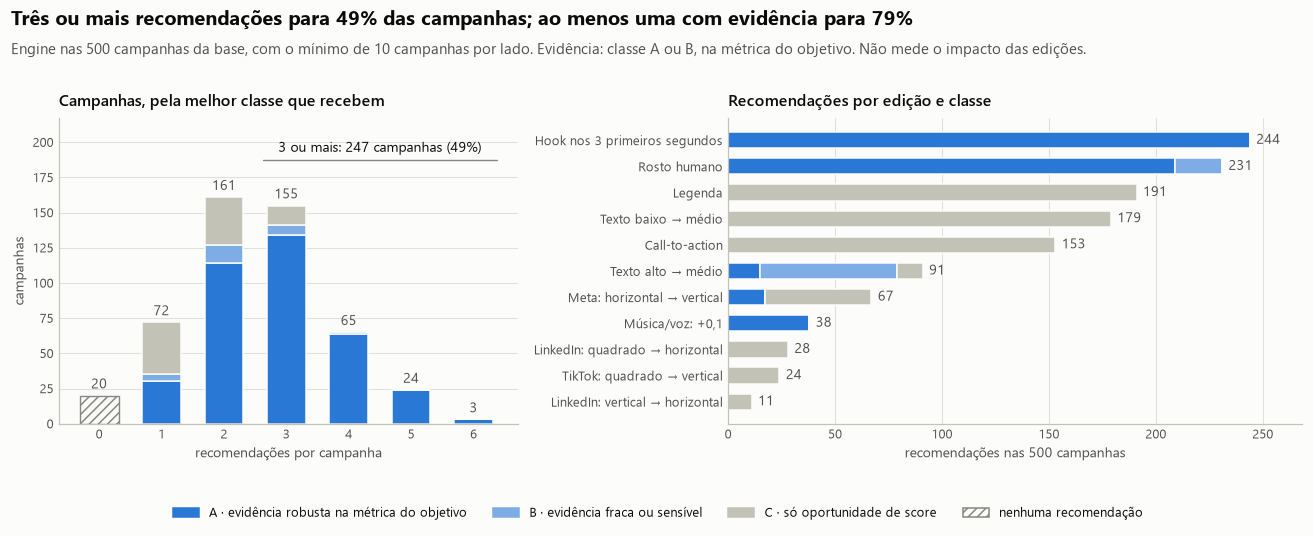

In [14]:
CLASS_COLORS = {"A": viz.ACCENT, "B": "#7eade5", "C": viz.CONTEXT}
CLASS_NAMES = {
    "A": "A · evidência robusta na métrica do objetivo",
    "B": "B · evidência fraca ou sensível",
    "C": "C · só oportunidade de score",
}
SHORT = {
    "hook": "Hook nos 3 primeiros segundos",
    "rosto": "Rosto humano",
    "cta": "Call-to-action",
    "legenda": "Legenda",
    "texto_alto_medio": "Texto alto → médio",
    "texto_baixo_medio": "Texto baixo → médio",
    "formato_meta_horizontal": "Meta: horizontal → vertical",
    "formato_tiktok_quadrado": "TikTok: quadrado → vertical",
    "formato_linkedin_vertical": "LinkedIn: vertical → horizontal",
    "formato_linkedin_quadrado": "LinkedIn: quadrado → horizontal",
    "musica": "Música/voz: +0,1",
}
# A ordem põe a classe primeiro: a classe da primeira recomendação é a melhor da campanha.
first_class = table[table["prioridade"] == 1].set_index("campanha_id")["classe"]
best = first_class.reindex(campaigns["campanha_id"]).fillna("nenhuma").to_numpy()
by_count = pd.crosstab(campaigns["recomendacoes"], best)
by_count = by_count.reindex(columns=["A", "B", "C", "nenhuma"], fill_value=0)
by_action = pd.crosstab(table["acao"], table["classe"]).reindex(columns=list("ABC"), fill_value=0)
by_action = by_action.loc[by_action.sum(axis=1).sort_values().index]

fig, (left, right) = plt.subplots(
    1, 2, figsize=(12, 4.9), gridspec_kw={"width_ratios": [1, 1.25]}
)
bottom = np.zeros(len(by_count))
for klass in "ABC":
    left.bar(by_count.index, by_count[klass], bottom=bottom, width=0.62,
             color=CLASS_COLORS[klass], edgecolor=viz.SURFACE, linewidth=1)
    bottom += by_count[klass].to_numpy()
left.bar(by_count.index, by_count["nenhuma"], width=0.62, color=viz.SURFACE,
         edgecolor=viz.INK_MUTED, linewidth=0.9, hatch="////")
totals = by_count.sum(axis=1)
for x, total in totals.items():
    left.text(x, total + 3, fmt_number(total), ha="center", va="bottom", fontsize=9,
              color=viz.INK_SECONDARY)
three = int(totals[totals.index >= 3].sum())
top = totals.max() + 26
left.plot([2.62, totals.index.max() + 0.38], [top, top], color=viz.INK_MUTED, linewidth=0.9)
left.text((3 + totals.index.max()) / 2, top + 4,
          f"3 ou mais: {three} campanhas ({fmt_pct(three / totals.sum(), 0)})",
          ha="center", va="bottom", fontsize=9, color=viz.INK)
left.set_ylim(0, top + 30)
left.set_xticks(by_count.index)
left.set_xlabel("recomendações por campanha")
left.set_ylabel("campanhas")
left.grid(axis="x", visible=False)
left.set_title("Campanhas, pela melhor classe que recebem")

rows = np.arange(len(by_action))
start = np.zeros(len(by_action))
for klass in "ABC":
    right.barh(rows, by_action[klass], left=start, height=0.62, color=CLASS_COLORS[klass],
               edgecolor=viz.SURFACE, linewidth=1)
    start += by_action[klass].to_numpy()
for row, total in zip(rows, by_action.sum(axis=1), strict=True):
    right.text(total + 3, row, fmt_number(total), va="center", fontsize=9,
               color=viz.INK_SECONDARY)
right.set_yticks(rows, [SHORT[key] for key in by_action.index])
right.set_xlim(0, by_action.sum(axis=1).max() * 1.1)
right.set_xlabel("recomendações nas 500 campanhas")
right.grid(axis="y", visible=False)
right.set_title("Recomendações por edição e classe")
handles = [Patch(color=CLASS_COLORS[k], label=CLASS_NAMES[k]) for k in "ABC"]
handles.append(Patch(facecolor=viz.SURFACE, edgecolor=viz.INK_MUTED, hatch="////",
                     label="nenhuma recomendação"))
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.0))
share_three = fmt_pct((campaigns["recomendacoes"] >= 3).mean(), 0)
share_evidence = fmt_pct((with_evidence >= 1).mean(), 0)
viz.add_header(
    fig,
    f"Três ou mais recomendações para {share_three} das campanhas; ao menos uma com evidência "
    f"para {share_evidence}",
    "Engine nas 500 campanhas da base, com o mínimo de 10 campanhas por lado. Evidência: classe "
    "A ou B, na métrica do objetivo. Não mede o impacto das edições.",
)
fig.subplots_adjust(bottom=0.2)
viz.save(fig, "04_avaliacao_engine")
plt.show()

- **Cobertura:** 247 campanhas (49,4%) recebem três ou mais recomendações, 161 recebem duas, 72 uma e 20 nenhuma. São 1.257 recomendações, 2,5 por campanha.
- **Evidência:** 395 campanhas (79%) têm ao menos uma recomendação com evidência na métrica do objetivo, e ela vem sempre em primeiro. Outras 85 (17%) recebem só oportunidades de score.
- **Três números lado a lado, porque três ou mais não quer dizer três melhorias comprovadas.** 247 campanhas recebem três ou mais recomendações; 395 recebem ao menos uma com evidência; só 34 recebem três ou mais com evidência. Das 247 com três ou mais, 14 recebem só oportunidades de score. É a cobertura alcançável com o catálogo e as evidências investigadas, não um máximo: outras edições, com evidência em dados novos, a ampliariam.
- **Composição:** 523 recomendações A (42%), 86 B (7%) e 648 C (52%). Hook e rosto concentram as A, e a música/voz soma 38; legenda, texto baixo → médio e CTA, que só têm a seu favor o score previsto, concentram as C.

### 11.2 De onde vêm as recomendações

Para cada edição do catálogo: quantas campanhas estão na plataforma e nas métricas da edição, quantas têm o valor ausente, quantas já têm outro valor (quem já tem hook, por exemplo, ou música/voz acima de 0,57) e quantas partem do valor atual da edição. Só estas são avaliadas.

In [15]:
funnel = action_funnel(evaluated).rename(
    columns={
        "campanhas": "campanhas na plataforma",
        "valor_ausente": "valor ausente",
        "outro_valor": "outro valor",
        "avaliadas": "avaliadas",
        "rejeitada": "rejeitadas",
    }
)
display(funnel)
print(f"Edições avaliadas e não recomendadas: {len(rejections(evaluated))}")
present = cleaned.set_index("campaign_id").loc[
    campaigns.loc[campaigns["recomendacoes"] == 0, "campanha_id"]
]
practices = present[["has_hook", "has_face", "has_cta"]].all(axis=1)
subtitle = present["has_subtitle"]
print(
    f"Campanhas sem recomendação: {len(present)}. Com hook, rosto e CTA: "
    f"{int(practices.sum())}; com texto médio: "
    f"{int(present['text_density'].eq('medium').sum())}; com legenda: "
    f"{int(subtitle.eq(True).sum())}; com legenda sem marcação: {int(subtitle.isna().sum())}"
)

,plataforma,metricas,campanhas na plataforma,valor ausente,outro valor,avaliadas,A,B,C,rejeitadas
acao,,,,,,,,,,
hook,todas,todas,500,0,256,244,244,0,0,0
rosto,todas,todas,500,0,269,231,209,22,0,0
cta,todas,todas,500,0,347,153,0,0,153,0
legenda,todas,todas,500,46,263,191,0,0,191,0
texto_alto_medio,todas,todas,500,0,409,91,15,64,12,0
texto_baixo_medio,todas,todas,500,0,321,179,0,0,179,0
formato_meta_horizontal,Meta,todas,241,0,174,67,17,0,50,0
formato_tiktok_quadrado,TikTok,todas,176,0,152,24,0,0,24,0
formato_linkedin_vertical,LinkedIn,todas,83,0,72,11,0,0,11,0


Edições avaliadas e não recomendadas: 0
Campanhas sem recomendação: 20. Com hook, rosto e CTA: 20; com texto médio: 20; com legenda: 16; com legenda sem marcação: 4


- **Com o mínimo padrão, nenhuma edição avaliada é rejeitada.** O filtro vem antes: uma edição só é avaliada quando a campanha parte exatamente do valor atual dela, e quem já tem hook não recebe hook. As regras de exclusão da seção 3.5 existem, mas não disparam nesta base com o mínimo de 10: nenhuma edição do catálogo tem associação desfavorável com p < 0,05 numa métrica de objetivo, todas têm o intervalo do score acima de zero, os formatos de destino têm pelo menos 44 campanhas na plataforma e toda comparação encontra 10 campanhas de cada lado, ao menos no recorte da plataforma. Elas atuam com o mínimo de 20 (seção 12) e em campanhas novas: combinação sem histórico, ROAS em Branding, score no limite da escala.
- **O filtro mais forte é o catálogo.** Duração e formato quadrado na Meta foram descartados na seção 8, e texto alto → baixo aparece só como alternativa na justificativa do texto médio.
- **A música/voz só é avaliada nas 60 campanhas de awareness.** Três não informam a proporção, 19 já passam de 0,57, e as 38 restantes recebem a sugestão, todas como A. Fora da retenção, ela não é avaliada, e por isso não gera nenhuma rejeição.
- **Valor ausente não vira sugestão.** As 46 campanhas com legenda sem marcação não recebem a sugestão de legenda: recebem um aviso. As 39 sem duração e as 38 sem música/voz também recebem aviso, porque o modelo usa a mediana do treino.
- **As 20 campanhas sem recomendação já seguem o catálogo:** todas têm hook, rosto humano, CTA e texto médio; 16 têm legenda e 4 estão sem marcação; e nenhuma está num formato com troca sugerida. A saída diz isso, sem completar a lista.

### 11.3 Plataforma, objetivo e categoria

In [16]:
SEGMENTS = {"plataforma": "platform", "objetivo": "objective", "categoria": "category"}
segments = {}
for column, key in SEGMENTS.items():
    order = CATEGORY_ORDERS[key]
    shares = coverage(campaigns, by=column).reindex(order)
    classes = pd.crosstab(table[column], table["classe"], normalize="index").reindex(order)
    segments[column] = pd.DataFrame(
        {
            "campanhas": shares["campanhas"],
            "média": shares["media"].map(lambda v: fmt_number(v, 1)),
            "nenhuma": shares["nenhuma"].map(lambda v: fmt_pct(v, 1)),
            "3 ou mais": shares["tres_ou_mais"].map(lambda v: fmt_pct(v, 1)),
            "com A ou B": shares["com_A_ou_B"].map(lambda v: fmt_pct(v, 1)),
            "só C": shares["so_C"].map(lambda v: fmt_pct(v, 1)),
            **{f"recomendações {k}": classes[k].map(lambda v: fmt_pct(v, 0)) for k in "ABC"},
        }
    )
display(pd.concat(segments, names=["recorte", "valor"]))

campanhas média nenhuma 3 ou mais com A ou B   só C  \
recorte    valor                                                              
plataforma Meta               241   2,5    5,0%     50,2%      76,3%  18,7%   
           TikTok             176   2,4    4,0%     46,6%      82,4%  13,6%   
           LinkedIn            83   2,7    1,2%     53,0%      79,5%  19,3%   
objetivo   conversions        165   2,5    3,0%     44,8%      81,8%  15,2%   
           traffic            150   2,4    5,3%     48,0%      76,0%  18,7%   
           engagement          79   2,6    2,5%     53,2%      73,4%  24,1%   
           awareness           60   2,9    3,3%     61,7%      90,0%   6,7%   
           app_install         46   2,3    6,5%     47,8%      73,9%  19,6%   
categoria  E-commerce         165   2,4    2,4%     45,5%      80,0%  17,6%   
           SaaS                97   2,6    4,1%     53,6%      83,5%  12,4%   
           Lead Gen            93   2,7    1,1%     54,8%      79,6%  19,4%   
           App Install         82   2,2   11,0%     43,9%      69,5%  19,5%   
           Branding            63   2,7    3,2%     52,4%      81,0%  15,9%   

                       recomendações A recomendações B recomendações C  
recorte    valor                                                        
plataforma Meta                    43%              5%             52%  
           TikTok                  43%              9%             48%  
           LinkedIn                36%              8%             56%  
objetivo   conversions             40%              7%             53%  
           traffic                 40%              8%             52%  
           engagement              42%              0%             58%  
           awareness               48%             13%             39%  
           app_install             42%              7%             52%  
categoria  E-commerce              40%              6%             54%  
           SaaS                    43%             10%             47%  
           Lead Gen                41%              4%             55%  
           App Install             42%              8%             50%  
           Branding                45%              7%             48%

- **A cobertura é parecida entre plataformas e categorias.** A parcela com três ou mais fica entre 43,9% (categoria App Install) e 54,8% (Lead Gen). A categoria App Install tem a maior parcela sem nenhuma recomendação (11%): mais criativos dela já seguem o catálogo.
- **O objetivo muda a classe e, em awareness, a cobertura.** Em engagement não há B: o texto alto → médio é inconclusivo no engajamento e vira C, e o rosto é robusto. Awareness tem a maior parcela de B (13%), porque na retenção o rosto é só indício, e também a maior cobertura: 61,7% das campanhas com três ou mais e 90% com alguma A ou B, porque só ali a música/voz é avaliada.
- **O formato depende da plataforma e do objetivo.** A troca de horizontal por vertical na Meta é A só em engagement (17 recomendações); nas outras 50, é C. As trocas de formato no TikTok e no LinkedIn são sempre C.

### 11.4 Quando a métrica do objetivo não acompanha o score

Toda recomendação C tem associação inconclusiva na métrica do objetivo. A tabela mostra em quantas a estimativa é desfavorável e em quantas há associação favorável em outra métrica.

In [17]:
c_recs = table[table["classe"] == "C"]
by_edit = c_recs.groupby("acao")
display(
    pd.DataFrame(
        {
            "recomendações C": by_edit.size(),
            "sinal desfavorável no objetivo": by_edit["sinal_desfavoravel"].sum(),
            "favorável em outra métrica": by_edit["outras_metricas_favoraveis"].apply(
                lambda s: int((s != "").sum())
            ),
        }
    ).sort_values("recomendações C", ascending=False)
)
unfavorable = (
    c_recs[c_recs["sinal_desfavoravel"]]
    .groupby(["acao", "objetivo", "metrica"])
    .agg(
        recomendações=("acao", "size"),
        efeito=("efeito", "first"),
        inferior=("ic_inferior", "first"),
        superior=("ic_superior", "first"),
    )
    .reset_index()
)
unfavorable["métrica do objetivo"] = unfavorable["metrica"].map(PERFORMANCE_METRICS)
unfavorable["associação (inconclusiva)"] = [
    f"{fmt_signed_pct(e, 1)} (de {fmt_signed_pct(lo)} a {fmt_signed_pct(hi)})"
    for e, lo, hi in zip(
        unfavorable["efeito"], unfavorable["inferior"], unfavorable["superior"], strict=True
    )
]
display(
    unfavorable.set_index(["acao", "objetivo"])[
        ["métrica do objetivo", "recomendações", "associação (inconclusiva)"]
    ]
)
b_recs = table[table["classe"] == "B"]
reason = np.where(b_recs["evidencia"] == "indício", "indício", "robusta, mas sensível")
display(
    pd.crosstab([b_recs["acao"], b_recs["objetivo"]], pd.Series(reason, index=b_recs.index))
    .rename_axis(columns="por que é B")
)

,recomendações C,sinal desfavorável no objetivo,favorável em outra métrica
acao,,,
legenda,191,0,0
texto_baixo_medio,179,32,0
cta,153,17,0
formato_meta_horizontal,50,14,50
formato_linkedin_quadrado,28,0,0
formato_tiktok_quadrado,24,16,0
texto_alto_medio,12,0,12
formato_linkedin_vertical,11,0,0


métrica do objetivo  \
acao                    objetivo                                     
cta                     awareness                         retenção   
formato_meta_horizontal awareness                         retenção   
                        traffic                                CTR   
formato_tiktok_quadrado app_install  conversões por mil impressões   
                        conversions  conversões por mil impressões   
                        traffic                                CTR   
texto_baixo_medio       engagement                     engajamento   

                                     recomendações associação (inconclusiva)  
acao                    objetivo                                              
cta                     awareness               17     −3,2% (de −13% a +8%)  
formato_meta_horizontal awareness                1    −7,6% (de −23% a +11%)  
                        traffic                 13   −12,3% (de −32% a +14%)  
formato_tiktok_quadrado app_install              2   −26,2% (de −52% a +13%)  
                        conversions              6   −26,2% (de −52% a +13%)  
                        traffic                  8   −22,3% (de −46% a +12%)  
texto_baixo_medio       engagement              32    −0,1% (de −18% a +21%)

por que é B                   indício  robusta, mas sensível
acao             objetivo                                   
rosto            awareness         22                      0
texto_alto_medio app_install        0                      7
                 conversions        0                     29
                 traffic           28                      0

- **Em 79 das 648 recomendações C, a estimativa na métrica do objetivo é desfavorável, sem significância.** São o CTA em awareness (retenção −3%), a troca de formato na Meta em traffic (CTR −12%) e em awareness, a troca de formato no TikTok em traffic, conversions e app_install (de −22% a −26%), e o texto baixo → médio em engagement (−0,1%, na prática nulo). Todas saem com aviso explícito, como hipóteses para teste; com p < 0,05, seriam excluídas.
- **Em 62 recomendações C, há associação favorável em outra métrica, e a saída a cita sem mudar a classe.** São a troca de formato na Meta em campanhas que não são de engagement (50), em que o formato se associa a +63% de engajamento, e o texto alto → médio em campanhas de engagement (12), em que o texto se associa a mais retenção, CTR e conversões.
- **As 86 recomendações B têm dois motivos.** São 50 indícios: o rosto em awareness (retenção +11%, p = 0,045) e o texto alto → médio em traffic (CTR +23%, p = 0,03). As outras 36 são robustas, mas sensíveis: o texto alto → médio em conversions e app_install depende das 5 correções por plausibilidade.

### 11.5 Ganho de score previsto

In [18]:
gains = table.groupby("acao").agg(
    recomendações=("acao", "size"),
    menor=("diferenca_score", "min"),
    maior=("diferenca_score", "max"),
    inferior=("score_modelo_inferior", "first"),
    superior=("score_modelo_superior", "first"),
    limítrofes=("limitrofe", "sum"),
)
gains = gains.sort_values("menor", ascending=False)
gains["ganho nas campanhas"] = [
    fmt_signed(low, 1)
    if round(low, 1) == round(high, 1)
    else f"{fmt_signed(low, 1)} a {fmt_signed(high, 1)}"
    for low, high in zip(gains["menor"], gains["maior"], strict=True)
]
gains["intervalo do modelo"] = [
    f"{fmt_signed(low, 2 if abs(low) < 0.05 else 1)} a {fmt_signed(high, 1)}"
    for low, high in zip(gains["inferior"], gains["superior"], strict=True)
]
display(gains[["recomendações", "ganho nas campanhas", "intervalo do modelo", "limítrofes"]])
print(
    f"Score previsto das 500 campanhas: de {fmt_number(campaigns['score_previsto'].min(), 1)} a "
    f"{fmt_number(campaigns['score_previsto'].max(), 1)}; maior score depois de uma edição: "
    f"{fmt_number(table['score_depois'].max(), 1)}"
)

,recomendações,ganho nas campanhas,intervalo do modelo,limítrofes
acao,,,,
hook,244,"+17,0","+15,7 a +18,5",0
texto_alto_medio,91,"+14,0","+12,0 a +16,1",0
rosto,231,"+11,8","+10,4 a +13,3",0
legenda,191,"+8,3","+6,8 a +9,8",0
cta,153,"+8,1","+6,6 a +9,5",0
formato_linkedin_vertical,11,"+8,1","+2,1 a +13,3",0
texto_baixo_medio,179,"+6,8","+5,3 a +8,3",0
formato_linkedin_quadrado,28,"+5,5","+1,6 a +9,5",0
formato_meta_horizontal,67,"+4,7","+2,6 a +6,8",0


Score previsto das 500 campanhas: de 15,5 a 90,5; maior score depois de uma edição: 93,9


- **A diferença de score de cada edição é a mesma em todas as campanhas em que ela aparece.** O modelo é aditivo, a diferença do formato muda só com a plataforma, e nenhuma campanha chega perto do limite da escala. Por isso, a distribuição é uma tabela: do hook (+17,0) à troca de quadrado por vertical no TikTok (+3,3). A música/voz é a única negativa (−0,5): nas 38 recomendações, a saída avisa que o score previsto cai.
- **Os menores ganhos são os de formato.** O do TikTok é limítrofe: o intervalo começa em +0,01, e as 24 recomendações levam o aviso de candidata experimental.
- **Score não é performance.** Legenda e CTA sobem mais de 8 pontos no modelo e não têm evidência em nenhuma métrica de objetivo. A troca de formato na Meta sobe só +4,7 e tem a associação mais forte com engajamento, +63%.

### 11.6 Música/voz

A única edição contínua e a única avaliada só numa métrica: a retenção, nas campanhas de awareness.

In [19]:
music_recs = table[table["acao"] == "musica"]
now = campaigns.set_index("campanha_id")["recomendacoes"]
without = now - now.index.isin(music_recs["campanha_id"])
display(
    pd.DataFrame(
        {
            "recomendações": len(music_recs),
            **{f"classe {k}": int((music_recs['classe'] == k).sum()) for k in "ABC"},
            **{
                f"risco {risk}": int((music_recs["risco"] == risk).sum())
                for risk in ["baixo", "moderado", "alto"]
            },
            "campanhas de 0 para 1": int(((without == 0) & (now == 1)).sum()),
            "campanhas de 2 para 3": int(((without == 2) & (now == 3)).sum()),
        },
        index=["música/voz +0,1"],
    )
)
positions = music_recs["prioridade"].value_counts().sort_index().to_dict()
print("Prioridade da música na lista:", positions)
print(
    "Score previsto cai em todas:",
    bool((music_recs["diferenca_score"] < 0).all()),
    "| ressalvas mais comuns:",
    music_recs["ressalvas"].value_counts().to_dict(),
)
display(
    music_recs[music_recs["risco"] == "alto"].set_index("campanha_id")[
        ["plataforma", "de", "para", "recorte", "campanhas_valor_atual", "campanhas_valor_sugerido"]
    ]
)

,recomendações,classe A,classe B,classe C,risco baixo,risco moderado,risco alto,campanhas de 0 para 1,campanhas de 2 para 3
"música/voz +0,1",38,38,0,0,0,36,2,3,10


Prioridade da música na lista: {1: 12, 2: 21, 3: 5}
Score previsto cai em todas: True | ressalvas mais comuns: {'score previsto cai · pouca base no contexto (só na plataforma)': 36, 'score previsto cai · pouca base no contexto (só na base inteira)': 2}


,plataforma,de,para,recorte,campanhas_valor_atual,campanhas_valor_sugerido
campanha_id,,,,,,
KLK-0306,LinkedIn,"com música/voz 0,48","com música/voz 0,58",todas as campanhas,63,64
KLK-0352,LinkedIn,"com música/voz 0,04","com música/voz 0,14",todas as campanhas,24,51


- **As 38 recomendações de música são A, e todas avisam que o score previsto cai.** Todas têm duas ressalvas curtas: score previsto cai e pouca base no contexto, só na plataforma em 36 e só na base inteira em 2. Nenhuma campanha de awareness tem 10 campanhas de cada lado num recorte com o objetivo, porque awareness tem só 60 campanhas.
- **O suporte fica no recorte da plataforma em 36 e na base inteira em 2.** São KLK-0306 (0,48) e KLK-0352 (0,04), ambas no LinkedIn, onde a plataforma não tem 10 campanhas em cada janela. As contagens descrevem a base de comparação; não estimam o efeito nesse recorte.
- **A música muda a faixa de cobertura de 13 das 38 campanhas.** Três passam de nenhuma recomendação para uma (KLK-0301, KLK-0328 e KLK-0460), e 10 passam de duas para três.
- **Na lista, ela vem depois de hook e texto, que têm associação maior com a retenção, e antes de B e C.** É a primeira em 12 campanhas: em 11, o que vem depois são só hipóteses de score, ou nada; só na KLK-0387 ela passa à frente de uma recomendação B, o rosto (+11% na retenção, só indício). Em 14 campanhas, o rosto B fica depois dela, e a nota de prioridade explica por quê.

## 12. Sensibilidade ao suporte mínimo

O mínimo de 10 campanhas de cada lado é operacional (seção 3.6). Aqui o engine roda de novo com 5 e com 20, sem mudar o padrão. O mínimo entra em três pontos: escolhe o recorte do suporte, e com ele o rótulo de risco; exige campanhas suficientes no formato de destino; e, quando a própria combinação de plataforma e formato tem menos campanhas que ele, abre cada recomendação com um aviso de extrapolação.

In [20]:
runs = {10: (evaluated, table, campaigns)}
for minimum in (5, 20):
    variant = RecommendationEngine(
        engine.predictor,
        load_performance_evidence(),
        load_score_differences(),
        min_support=minimum,
    )
    variant_reports = variant.recommend_all(cleaned)
    runs[minimum] = (
        variant_reports,
        recommendation_table(variant_reports),
        campaign_table(variant_reports),
    )
runs = dict(sorted(runs.items()))
display(
    pd.DataFrame(
        {
            f"mínimo {minimum}": {
                "recomendações": len(t),
                "campanhas com 3 ou mais": int((c["recomendacoes"] >= 3).sum()),
                "campanhas sem nenhuma": int((c["recomendacoes"] == 0).sum()),
                **{f"classe {k}": int((t["classe"] == k).sum()) for k in "ABC"},
                "avaliadas e não recomendadas": len(rejections(r)),
                "recorte plataforma, categoria e objetivo": fmt_pct(
                    (t["recorte"] == "plataforma, categoria e objetivo").mean(), 0
                ),
                "risco moderado ou alto": fmt_pct((t["risco"] != "baixo").mean(), 0),
                "com aviso de extrapolação": int(t["extrapolacao"].sum()),
                "música/voz: moderado / alto": " / ".join(
                    str(int(((t['acao'] == 'musica') & (t['risco'] == risk)).sum()))
                    for risk in ["moderado", "alto"]
                ),
            }
            for minimum, (r, t, c) in runs.items()
        }
    )
)

,mínimo 5,mínimo 10,mínimo 20
recomendações,1257,1257,1246
campanhas com 3 ou mais,247,247,245
campanhas sem nenhuma,20,20,21
classe A,523,523,523
classe B,86,86,86
classe C,648,648,637
avaliadas e não recomendadas,0,0,11
"recorte plataforma, categoria e objetivo",67%,28%,5%
risco moderado ou alto,11%,32%,62%
com aviso de extrapolação,0,0,28


In [21]:
moderate = {
    f"mínimo {minimum}": pd.concat(
        {
            column: t.groupby(column)["risco"]
            .apply(lambda s: (s != "baixo").mean())
            .reindex(CATEGORY_ORDERS[key])
            for column, key in list(SEGMENTS.items())[:2]
        }
    )
    for minimum, (_, t, _) in runs.items()
}
print("Recomendações com risco de extrapolação moderado ou alto:")
display(pd.DataFrame(moderate).map(lambda v: fmt_pct(v, 0)))

formats = pd.DataFrame(
    [
        {
            "edição": action.key,
            "campanhas com o formato atual": engine.predictor.support.count(
                platform=action.platform, format=action.current
            ),
            "com o formato sugerido": engine.predictor.support.count(
                platform=action.platform, format=action.target
            ),
        }
        for action in ACTIONS
        if action.field == "format"
    ]
).set_index("edição")
formats["sai com mínimo acima de"] = formats.min(axis=1)
display(formats)

keys = {
    minimum: set(zip(t["campanha_id"], t["acao"], strict=True))
    for minimum, (_, t, _) in runs.items()
}
for minimum in (5, 20):
    gained, lost = keys[minimum] - keys[10], keys[10] - keys[minimum]
    print(
        f"Mínimo {minimum} contra 10: {len(gained)} recomendações a mais, {len(lost)} a menos "
        f"({', '.join(sorted({action for _, action in lost})) or 'nenhuma'})"
    )
counts = pd.DataFrame(
    {minimum: c.set_index("campanha_id")["recomendacoes"] for minimum, (_, _, c) in runs.items()}
)
print("Campanhas cujo número de recomendações muda com 20:")
display(counts[counts[20] != counts[10]].rename(columns=lambda m: f"mínimo {m}"))
for minimum in (5, 20):
    common = table.merge(runs[minimum][1], on=["campanha_id", "acao"], suffixes=("", "_outro"))
    changed = (common["prioridade"] != common["prioridade_outro"]).sum()
    risk = (common["risco"] != common["risco_outro"]).sum()
    print(
        f"Mínimo {minimum}: {len(common)} recomendações em comum com o padrão; "
        f"{changed} mudam de prioridade e {risk} mudam de risco"
    )

Recomendações com risco de extrapolação moderado ou alto:


mínimo 5 mínimo 10 mínimo 20
plataforma Meta              4%       19%       48%
           TikTok            8%       32%       64%
           LinkedIn         36%       65%      100%
objetivo   conversions       1%       11%       26%
           traffic           0%        9%       53%
           engagement       19%       40%      100%
           awareness        40%       80%      100%
           app_install      25%       91%      100%

,campanhas com o formato atual,com o formato sugerido,sai com mínimo acima de
edição,,,
formato_meta_horizontal,67,106,67
formato_tiktok_quadrado,24,152,24
formato_linkedin_vertical,11,44,11
formato_linkedin_quadrado,28,44,28


Mínimo 5 contra 10: 0 recomendações a mais, 0 a menos (nenhuma)
Mínimo 20 contra 10: 0 recomendações a mais, 11 a menos (formato_linkedin_vertical)
Campanhas cujo número de recomendações muda com 20:


,mínimo 5,mínimo 10,mínimo 20
campanha_id,,,
KLK-0089,4,4,3
KLK-0116,6,6,5
KLK-0155,3,3,2
KLK-0198,1,1,0
KLK-0229,5,5,4
KLK-0249,3,3,2
KLK-0250,2,2,1
KLK-0262,4,4,3
KLK-0265,5,5,4


Mínimo 5: 1257 recomendações em comum com o padrão; 0 mudam de prioridade e 257 mudam de risco
Mínimo 20: 1246 recomendações em comum com o padrão; 0 mudam de prioridade e 400 mudam de risco


- **A lista e a ordem quase não dependem do mínimo.** Com 5, saem as mesmas 1.257 recomendações. Com 20, saem 11: a troca de vídeo vertical por horizontal no LinkedIn, porque a plataforma só tem 11 vídeos verticais. Duas campanhas caem de três para duas recomendações (KLK-0155 e KLK-0249) e uma fica sem nenhuma (KLK-0198). Entre as recomendações que ficam, nenhuma muda de prioridade: o suporte não entra na ordem, só nos avisos.
- **O que muda é o recorte do suporte e o rótulo de risco.** O risco moderado ou alto vai de 11% das recomendações, com mínimo 5, a 32%, com 10, e 62%, com 20. LinkedIn e os objetivos com menos campanhas, app_install, awareness e engagement, são os primeiros a cair para o recorte da plataforma.
- **A música continua elegível em todos os mínimos.** Muda só o recorte: com 5, 37 ficam na plataforma e 1 na base inteira; com 10, 36 e 2; com 20, 27 e 11. O agregado é estável, mas o risco de cada campanha depende da largura das janelas e do mínimo.
- **Com 20, os vídeos verticais do LinkedIn viram uma combinação rara.** As 28 recomendações que essas campanhas mantêm passam a abrir com o aviso de extrapolação.
- **Cada troca de formato tem seu limite.** A do LinkedIn vertical sai com mínimo acima de 11; a do TikTok quadrado, acima de 24; a do LinkedIn quadrado, acima de 28; a da Meta, acima de 67.
- **Por que o padrão continua 10.** Com 5, comparações de 5 a 9 campanhas de cada lado passariam a ter risco baixo. Com 20, uma edição com 11 campanhas de um lado sumiria, e 62% das recomendações ficariam com risco moderado ou alto. Dez é o ponto em que o engine mantém o catálogo inteiro e ainda usa o contexto da campanha quando há base para isso.

## 13. Robustez da ordem

A ordem do engine põe a classe primeiro e, dentro dela, a estimativa na métrica do objetivo (A e B) ou o limite inferior do intervalo do score (C). As ordens abaixo são diagnósticos: a ordem aprovada continua a padrão. Só contam as 408 campanhas com duas ou mais recomendações.

In [22]:
robustness, swaps = order_robustness(table)
display(
    robustness.rename(
        columns={
            "criterio": "critério",
            "primeira_muda": "primeira recomendação muda",
            "ordem_muda": "ordem muda",
        }
    )
)
display(swaps.set_index(["ordem", "de", "para"]))

,critério,campanhas,primeira recomendação muda,ordem muda
ordem,,,,
só impacto,"estimativa na métrica do objetivo, sem olhar a classe",408,23,68
conservadora,"limite inferior do intervalo na métrica do objetivo, sem olhar a classe",408,3,11
só score,ganho de score previsto para a campanha,408,47,87
sensível como A,"como a do engine, mas a evidência robusta e sensível à análise conta como A",408,5,12
suporte primeiro,"como a do engine, mas dentro de cada classe o risco de extrapolação menor vem antes",408,4,17
C pela estimativa,"como a do engine, mas a classe C segue a estimativa pontual do score",408,0,3
qualquer uma,alguma das alternativas acima,408,62,118


campanhas
ordem            de                      para                                
só impacto       musica                  legenda                            6
                 rosto                   texto_alto_medio                   5
                 texto_baixo_medio       formato_linkedin_quadrado          3
                 rosto                   formato_linkedin_vertical          2
                 legenda                 formato_tiktok_quadrado            1
                 cta                     formato_tiktok_quadrado            1
                 rosto                   formato_linkedin_quadrado          1
                 legenda                 formato_linkedin_quadrado          1
                 musica                  formato_linkedin_quadrado          1
                                         rosto                              1
                 hook                    formato_linkedin_quadrado          1
conservadora     texto_alto_medio        legenda                            3
só score         rosto                   hook                              12
                                         texto_alto_medio                  10
                 formato_meta_horizontal hook                               7
                                         rosto                              6
                 musica                  legenda                            6
                 formato_meta_horizontal legenda                            2
                                         texto_baixo_medio                  1
                 musica                  cta                                1
                                         formato_linkedin_quadrado          1
                                         rosto                              1
sensível como A  rosto                   texto_alto_medio                   5
suporte primeiro legenda                 cta                                2
                                         texto_baixo_medio                  1
                 texto_alto_medio        legenda                            1

- **A primeira recomendação é a mesma nas seis alternativas em 346 das 408 campanhas.** A ordem completa muda em 118.
- **Só impacto (23 campanhas).** Sem a classe, estimativas inconclusivas e muito incertas passariam à frente: a legenda passaria a música em 6 campanhas de awareness (+8% contra +3,9%, mas inconclusiva), e as trocas de formato no LinkedIn e no TikTok passariam outras edições. Em 5 casos, o texto alto → médio, que é B por depender das correções por plausibilidade, passaria o rosto. É o motivo de a classe vir primeiro.
- **Conservadora (3).** Ordenar pelo limite inferior da associação quase não muda nada: a classe já separa as associações com limite acima de zero. As 3 trocas acontecem em campanhas só com recomendações C, em que a ordem passaria a seguir intervalos inconclusivos.
- **Só score (47).** É a divergência mais frequente: o modelo de score pesa mais o hook e o texto do que a associação com a métrica do objetivo. Em campanhas de engagement, o rosto e a troca de formato na Meta, que têm as maiores associações com engajamento, cairiam para trás de edições com mais score, como o hook. Em outras, o texto alto → médio (+14 de score) passaria o rosto (+11,8). A música, com score em queda, cairia para o fim: nas 9 campanhas em que ela vem em primeiro e há outras recomendações, outra edição passaria à frente, quase sempre uma hipótese de score.
- **Sensível como A (5).** Se a evidência robusta e sensível contasse como A, o texto alto → médio passaria o rosto em 5 campanhas.
- **Suporte primeiro (4) e C pela estimativa (0).** Preferir o recorte mais específico dentro da classe troca a primeira recomendação em 4 campanhas, todas entre oportunidades de score. Ordenar a classe C pela estimativa pontual do score, e não pelo limite inferior, nunca muda a primeira.

Os conflitos entre critérios, contados em pares de recomendações da mesma campanha:

In [23]:
display(
    conflicts(table).rename(
        columns={
            "par_mais_comum": "par mais comum",
            "pares_mais_comum": "pares do mais comum",
        }
    )
)
sensitive = table[(table["classe"] == "B") & (table["evidencia"] == "robusto")]
print(f"Recomendações B robustas, mas sensíveis à análise: {len(sensitive)}")

,pares,campanhas,par mais comum,pares do mais comum
conflito,,,,
classe × magnitude,65,47,musica antes de legenda,15
score × associação,140,87,rosto antes de texto_alto_medio,30
impacto × suporte,52,29,musica antes de rosto,6
incerteza na classe C,3,3,texto_baixo_medio antes de formato_linkedin_vertical,3


Recomendações B robustas, mas sensíveis à análise: 36


- **Classe × magnitude (65 pares, em 47 campanhas).** A maior parte vem da música: em awareness, ela é A com +3,9% e fica antes da legenda (C, +8% inconclusivo, 15 pares), do rosto (B, +11% só indício, 14 pares) e de outras estimativas maiores, mas mais fracas. Em 12 pares, o rosto (A) vem antes do texto alto → médio (B), que tem estimativa maior em conversões, mas sensível; nos demais, uma troca de formato no LinkedIn (C) tem estimativa inconclusiva maior, com intervalos enormes. A saída explica a inversão na nota de prioridade.
- **Score × associação (140 pares).** A recomendação de baixo tem mais score. Os casos mais comuns são o texto alto → médio (+14) abaixo do rosto (+11,8), o hook (+17) abaixo do rosto ou da troca de formato na Meta em engagement e, em 55 pares, qualquer edição abaixo da música, que tem score em queda. O engine segue a métrica avaliada e mostra os dois números.
- **Impacto × suporte (52 pares).** A recomendação de cima usa um recorte de suporte mais amplo que a de baixo; em 15 deles, é a música, que nunca chega a um recorte com o objetivo. O suporte não entra na ordem: vira aviso de risco.
- **Incerteza na classe C (3 pares).** A troca de vertical por horizontal no LinkedIn tem estimativa de score maior que o texto baixo → médio (+8,1 contra +6,8), mas o intervalo dela começa em +2,1; fica depois.
- **Robusto × sensível à plausibilidade.** São as 36 recomendações B robustas, mas sensíveis. O efeito delas na ordem é o da alternativa "sensível como A".

## 14. Casos representativos e adversos

Campanhas reais da base, escolhidas para cobrir as situações que o engine precisa tratar, e duas variações fora do histórico. A leitura de cada caso, abaixo da tabela, é escrita para o time de marketing.

In [24]:
strict = RecommendationEngine(
    engine.predictor, load_performance_evidence(), load_score_differences(), min_support=20
)
featured = {
    "KLK-0203": "três recomendações com evidência",
    "KLK-0001": "awareness: hook e música/voz",
    "KLK-0044": "nenhuma recomendação",
    "KLK-0030": "objetivo engagement, vídeo horizontal na Meta",
    "KLK-0191": "objetivo traffic, vídeo horizontal na Meta",
    "KLK-0048": "vídeo quadrado no TikTok",
    "KLK-0198": "vídeo vertical no LinkedIn",
    "KLK-0068": "legenda e música/voz ausentes",
    "KLK-0013": "três recomendações, nenhuma com evidência",
    "KLK-0352": "música/voz com base só no histórico inteiro",
}
case_reports = {
    f"{cid} · {about}": engine.recommend(history.loc[[cid]]) for cid, about in featured.items()
}
case_reports["KLK-0229 · vídeo vertical no LinkedIn, com mínimo de 20"] = strict.recommend(
    history.loc[["KLK-0229"]]
)
case_reports["Nova · TikTok, vídeo horizontal, sem histórico"] = engine.recommend(
    {**example, "format": "horizontal"}
)
display(
    pd.DataFrame(
        [
            {
                "caso": name,
                "contexto": " · ".join(
                    [
                        report.campaign["platform"],
                        report.campaign["objective"],
                        f"vídeo {report.campaign['format']}",
                    ]
                ),
                "recomendações, em ordem": " > ".join(
                    f"{SHORT[r.action]} ({r.recommendation_class})"
                    for r in report.recommendations
                )
                or "nenhuma",
                "avisos": sum(len(r.warnings) for r in report.recommendations)
                + len(report.notes),
            }
            for name, report in case_reports.items()
        ]
    ).set_index("caso")
)

,contexto,"recomendações, em ordem",avisos
caso,,,
KLK-0203 · três recomendações com evidência,Meta · awareness · vídeo vertical,"Hook nos 3 primeiros segundos (A) > Texto alto → médio (A) > Música/voz: +0,1 (A) > Rosto humano (B) > Legenda (C)",7
KLK-0001 · awareness: hook e música/voz,Meta · awareness · vídeo vertical,"Hook nos 3 primeiros segundos (A) > Música/voz: +0,1 (A)",4
KLK-0044 · nenhuma recomendação,LinkedIn · awareness · vídeo horizontal,nenhuma,2
"KLK-0030 · objetivo engagement, vídeo horizontal na Meta",Meta · engagement · vídeo horizontal,Meta: horizontal → vertical (A) > Rosto humano (A) > Hook nos 3 primeiros segundos (A),0
"KLK-0191 · objetivo traffic, vídeo horizontal na Meta",Meta · traffic · vídeo horizontal,Meta: horizontal → vertical (C),2
KLK-0048 · vídeo quadrado no TikTok,TikTok · awareness · vídeo quadrado,Hook nos 3 primeiros segundos (A) > Texto alto → médio (A) > TikTok: quadrado → vertical (C),4
KLK-0198 · vídeo vertical no LinkedIn,LinkedIn · app_install · vídeo vertical,LinkedIn: vertical → horizontal (C),2
KLK-0068 · legenda e música/voz ausentes,TikTok · conversions · vídeo vertical,Texto alto → médio (B) > Call-to-action (C),4
"KLK-0013 · três recomendações, nenhuma com evidência",TikTok · engagement · vídeo quadrado,Call-to-action (C) > Texto baixo → médio (C) > TikTok: quadrado → vertical (C),7


- **KLK-0203, Meta, awareness: quatro recomendações com evidência.** Hook e texto médio no lugar do alto têm associação robusta com a retenção, a métrica de awareness. A música/voz, de 0,17 para 0,27, vem em terceiro, como A, com a ressalva de que o score previsto cai. O rosto humano entra como B: na retenção, a associação é só um indício, embora seja robusta em CTR, engajamento e conversões. A legenda fecha a lista como hipótese: o modelo prevê mais score, mas a base não mostra ganho na retenção.
- **KLK-0001, Meta, awareness: hook e música/voz.** O criativo já tem rosto, CTA, legenda e texto médio. Com evidência na retenção, sobram o hook e a música, de 0,39 para 0,49; o engine diz que são menos de três e não completa a lista.
- **KLK-0044, LinkedIn, awareness: nenhuma recomendação.** O criativo tem hook, rosto, CTA e texto médio, no vídeo horizontal, o formato mais comum do LinkedIn. A legenda está sem marcação, então o engine não a sugere; a música/voz está ausente, e a saída avisa que o modelo usa a mediana e que o engine não sugere mudá-la.
- **KLK-0030 e KLK-0191, Meta, vídeo horizontal: o objetivo muda a recomendação.** Na campanha de engagement, trocar para vertical vem primeiro, como A: na Meta, o vertical se associa a +63% de engajamento. Na de traffic, a mesma troca é a única sugestão e fica como C, com aviso de que a estimativa no CTR é desfavorável (−12%), embora inconclusiva.
- **KLK-0048, TikTok, vídeo quadrado.** A troca para vertical é C e limítrofe: o intervalo do ganho de score começa em +0,01. É uma candidata experimental, depois de hook e texto médio, que têm evidência. A campanha é de awareness, mas a música/voz, 0,73, já passa de 0,57.
- **KLK-0198, LinkedIn, vídeo vertical.** A única sugestão é trocar para horizontal, como C e com pouca base: a plataforma tem 11 vídeos verticais. Com mínimo de 20, ela sumiria.
- **KLK-0068, TikTok, conversions, com dados ausentes.** A legenda está sem marcação e a música/voz, ausente. O engine não sugere legenda e avisa sobre as duas ausências; recomenda texto médio (B) e CTA (C).
- **KLK-0013, TikTok, engagement: três recomendações, nenhuma com evidência.** CTA, texto baixo → médio e vídeo vertical sobem o score previsto, mas nenhuma tem evidência de ganho no engajamento: são hipóteses para testar, não melhorias comprovadas. O texto tem estimativa de −0,1% no engajamento, na prática nula, e o formato é limítrofe.
- **KLK-0352, LinkedIn, awareness: música com base só no histórico inteiro.** A música/voz, de 0,04 para 0,14, é a única recomendação com evidência. No LinkedIn não há 10 campanhas em cada janela, e o suporte vem da base inteira, com risco alto; a ressalva curta diz isso: pouca base no contexto (só na base inteira). A troca de quadrado por horizontal vem depois, como hipótese de score.
- **KLK-0229 com mínimo de 20: combinação rara.** Com esse mínimo, os 11 vídeos verticais do LinkedIn não bastam. Hook, rosto, texto e CTA continuam, cada um aberto por um aviso de extrapolação, e a troca de formato sai.
- **Campanha nova no TikTok com vídeo horizontal: combinação sem histórico.** Ficam o hook (A) e o texto (B), com aviso de extrapolação. CTA e legenda, que só sobem o score, saem: sem evidência e sem histórico, o ganho viria só de uma previsão fora da base.

A saída completa do caso mais delicado, KLK-0013, mostra como o engine comunica recomendações sem evidência na métrica do objetivo. No resumo executivo, nenhuma é chamada de melhoria, e cada uma traz todas as ressalvas:

In [25]:
print(case_reports["KLK-0013 · três recomendações, nenhuma com evidência"].to_text())

Campanha KLK-0013 · TikTok · Lead Gen · engagement · público 35-44 · sem retargeting
Métrica do objetivo: engajamento
Score previsto: 66,9 (observado: 77,2)

3 recomendações, todas hipóteses de score (classe C), sem evidência suficiente na métrica do objetivo.

Principais recomendações:
   1. Incluir um call-to-action · classe C
      Klike Score +8,1 pontos; sem evidência suficiente em engajamento
      Ressalvas: sem evidência na métrica
   2. Aumentar o texto na tela de baixo para médio · classe C
      Klike Score +6,8 pontos; sem evidência suficiente em engajamento
      Ressalvas: sem evidência na métrica · estimativa desfavorável e inconclusiva · pouca base no contexto (só na plataforma)
   3. Trocar o vídeo quadrado por vertical · classe C
      Klike Score +3,3 pontos; sem evidência suficiente em engajamento
      Ressalvas: sem evidência na métrica · ganho de score limítrofe · pouca base no contexto (só na plataforma)

Em detalhe:

1. Incluir um call-to-action  [classe C: opo

## 15. Verificação de ponta a ponta

A função `audit` roda o engine num conjunto de campanhas e confere, relatório a relatório: se JSON, tabela e texto mostram as mesmas recomendações, na mesma ordem, com a mesma classe, impacto, avisos e ressalvas curtas; se o resumo executivo mostra as primeiras recomendações, iguais no texto e no JSON; se uma métrica escolhida manualmente é declarada, sem nenhum texto chamá-la de métrica do objetivo; se a música só é avaliada na retenção; se as prioridades vão de 1 a n; se nenhum campo é editado duas vezes e nada do contexto da campanha é editado; se cada edição parte do valor atual da campanha, o que impede tratar valor ausente como ausência; se os scores ficam entre 0 e 100; se a classe segue a regra e os números batem com as tabelas de evidência; se o suporte tem o mínimo dos dois lados; se cada aviso aparece exatamente quando o campo correspondente pede, e se as ressalvas curtas são os rótulos desses avisos, na ordem de precedência; e, na música, se a edição soma 0,1 ao valor exato e não passa de 0,67. Depois, roda tudo de novo em ordem inversa, para conferir o determinismo, e só com os 13 campos de pré-publicação, para conferir que as métricas observadas não entram no cálculo.

Além das 500 campanhas, entram campanhas novas que a base não cobre: o exemplo do repositório, criativos completos em vários formatos, vídeo horizontal no TikTok, um criativo com legenda e duração ausentes, três criativos de awareness com música/voz 0,333, 0,57 e 0,571, e um sem música/voz. A terceira coluna roda as mesmas campanhas novas com a retenção escolhida manualmente.

In [26]:
new_campaigns = pd.DataFrame(
    [
        example,
        complete,
        {**complete, "format": "quadrado"},
        {**complete, "platform": "LinkedIn", "format": "vertical"},
        {**complete, "platform": "Meta", "format": "horizontal", "objective": "traffic"},
        {**example, "format": "horizontal"},
        {**example, "has_subtitle": None, "video_duration_s": None},
        *[
            {**complete, "objective": "awareness", "music_voice_ratio": value}
            for value in [0.333, 0.57, 0.571]
        ],
        {**complete, "objective": "awareness", "music_voice_ratio": None},
    ]
)
checks = pd.concat(
    {
        "500 campanhas da base": audit(engine, cleaned),
        f"{len(new_campaigns)} campanhas novas": audit(engine, new_campaigns),
        "as mesmas, com retenção escolhida": audit(
            engine, new_campaigns, metric="completion_rate"
        ),
    },
    axis=1,
)
display(checks)
failures = int(checks.xs("falhas", axis=1, level=1).sum().sum())
print(f"Verificações: {len(checks)} | falhas: {failures}")

500 campanhas da base  \
                                                                               itens   
verificacao                                                                            
JSON, tabela e texto mostram as mesmas recomendações                             500   
resumo coerente com a lista                                                      500   
resumo executivo igual às primeiras recomendações                                500   
métrica escolhida manualmente declarada                                          500   
música avaliada só na retenção                                                   500   
prioridades de 1 a n                                                             500   
no máximo uma edição por campo                                                   500   
contexto da campanha nunca é editado                                             500   
nenhuma oportunidade só de score numa combinação sem histórico                   500   
cada edição parte do valor atual da campanha                                    1257   
score antes e depois entre 0 e 100                                              1257   
classe coerente com a evidência                                                 1257   
números iguais aos das tabelas de evidência                                     1257   
suporte com o mínimo nos dois lados                                             1257   
avisos coerentes com os campos                                                  1257   
ressalvas curtas iguais aos avisos                                              1257   
música só na retenção, +0,1 e até 0,67                                            38   
mesma saída ao rodar de novo, em outra ordem                                     500   
mesma saída sem as métricas observadas                                           500   

                                                                       \
                                                               falhas   
verificacao                                                             
JSON, tabela e texto mostram as mesmas recomendações                0   
resumo coerente com a lista                                         0   
resumo executivo igual às primeiras recomendações                   0   
métrica escolhida manualmente declarada                             0   
música avaliada só na retenção                                      0   
prioridades de 1 a n                                                0   
no máximo uma edição por campo                                      0   
contexto da campanha nunca é editado                                0   
nenhuma oportunidade só de score numa combinação sem histórico      0   
cada edição parte do valor atual da campanha                        0   
score antes e depois entre 0 e 100                                  0   
classe coerente com a evidência                                     0   
números iguais aos das tabelas de evidência                         0   
suporte com o mínimo nos dois lados                                 0   
avisos coerentes com os campos                                      0   
ressalvas curtas iguais aos avisos                                  0   
música só na retenção, +0,1 e até 0,67                              0   
mesma saída ao rodar de novo, em outra ordem                        0   
mesma saída sem as métricas observadas                              0   

                                                               11 campanhas novas  \
                                                                            itens   
verificacao                                                                         
JSON, tabela e texto mostram as mesmas recomendações                           11   
resumo coerente com a lista                                                    11   
resumo executivo igual às primeiras recomendações                              11   
métrica e

Verificações: 19 | falhas: 0


As 19 verificações passam, com zero falhas, nas três colunas. Os testes automatizados cobrem o que a tabela não cobre: entradas inválidas e campos desconhecidos, métrica incompatível como ROAS em Branding, o catálogo sem duas edições do mesmo campo, a linha de comando com a mesma saída da API, em texto e em JSON, a tabela salva em `reports/` igual a uma rodada nova do engine, a elegibilidade da música no valor exato, as janelas do suporte contra uma contagem manual em inteiros, os avisos de score em queda e de limite da escala quando os dois se aplicam, e o motivo de rejeição quando o intervalo do score não fica acima de zero. As estimativas muito perto de zero aparecem com uma casa decimal, como −0,1%, para não parecerem nulas.

## 16. Conclusões e limitações

**O que a avaliação mostra:**

- **Cobertura:** 247 campanhas (49,4%) recebem três ou mais recomendações e 20 (4%) nenhuma. O limite é o catálogo, não as regras: com o mínimo padrão, toda edição avaliada vira recomendação, e quem recebe menos de três já segue a maior parte das práticas.
- **Evidência:** 395 campanhas (79%) recebem ao menos uma recomendação com evidência na métrica do objetivo, sempre em primeiro, mas só 34 recebem três ou mais com evidência. Mais da metade das recomendações (52%) é só oportunidade de score, e a saída diz isso em cada uma.
- **Música/voz:** 38 recomendações A, só em awareness, todas com o aviso de que o score previsto cai e com pouca base no contexto. Ela acrescenta uma recomendação a 38 campanhas e muda a faixa de cobertura de 13: três passam a ter uma recomendação, e dez passam de duas para três.
- **Coerência:** as 19 verificações passam nas 500 campanhas e nas campanhas novas, inclusive com a métrica escolhida manualmente.
- **Robustez:** entre 5 e 20 campanhas por lado, o mínimo muda o recorte e o rótulo de risco, não a lista nem a ordem, exceto nos 11 vídeos verticais do LinkedIn. A primeira recomendação é a mesma nas seis ordens alternativas em 346 das 408 campanhas com duas ou mais.
- **Conflitos visíveis:** quando score e métrica do objetivo discordam, a ordem segue a métrica do objetivo, e a saída mostra os dois números.

**O que ela não mostra:** o impacto das edições. A avaliação usa as mesmas campanhas que geraram as evidências e o modelo, e nenhuma delas foi observada depois de uma edição. O próximo passo é testar em A/B, começando pelas recomendações A mais frequentes: hook e rosto humano.

**Limitações:**

- **O catálogo é pequeno.** São 11 edições, e só 5 têm evidência de performance em algum objetivo. Muitos criativos já seguem as práticas com evidência e recebem menos de três recomendações.
- **A música/voz é uma associação pequena e linear.** O ganho associado é de 3,9% de retenção a cada +0,1, uma proxy de atenção, e vem com score em queda. Pela regra de prioridade, uma A pequena fica antes de uma B maior, como o rosto na retenção.
- **Os efeitos são gerais.** O engine não estima efeitos próprios por segmento; o contexto entra pelo que se aplica à campanha, pela métrica do objetivo, pelo formato dentro da plataforma e pelo suporte.
- **Cada edição é avaliada sozinha.** O engine não soma efeitos de edições combinadas.
- **O score vem de um modelo aditivo.** O ganho de uma edição é o mesmo para todas as campanhas da plataforma, exceto perto dos limites da escala; o engine não o apresenta como um cálculo sob medida para aquele vídeo.
- **A avaliação é na própria base.** Cobertura e coerência são medidas nas campanhas que alimentaram as evidências e o modelo. Isso descreve o comportamento do engine; não valida as recomendações.
- **O mínimo de 10 campanhas por lado é operacional.** Entre 5 e 20, ele muda sobretudo o rótulo de risco (seção 12). Na música, o suporte é uma aproximação por janelas de 0,10.
- **Associação, não causa.** Toda recomendação traz um teste A/B como próximo passo.